# Use LLM to get synonyms for species annotations

In [17]:
import os
import sys
import re
import json
import pandas as pd
import numpy as np
import requests
import csv
import time
from openai import OpenAI
import libsbml
import antimony
from io import StringIO
from dataclasses import dataclass
from typing import List, Dict, Tuple, Any, Optional, Set
import matplotlib.pyplot as plt
import seaborn as sns
import traceback

# Import AMAS package
sys.path.insert(0, '/Users/luna/Desktop/CRBM/AMAS_proj/AMAS-v2')
from AMAS import recommender
from AMAS import constants as cn
from AMAS import tools

# Directory paths
biomd_model_dir = '/Users/luna/Desktop/CRBM/AMAS_proj/Models/BioModels'
output_dir = '/Users/luna/Desktop/CRBM/AMAS_proj/Results/LLM_results/'

# test model
model_file = "/Users/luna/Desktop/CRBM/AMAS_proj/AMAS-v2/tests/BIOMD0000000190.xml"


In [18]:
developer_prompt = f"""You are a biomedical knowledge assistant. Your task is to normalize species names from biochemical 
models into standardized or canonical chemical names or common synonyms for ontology lookup on ChEBI. Only consider them as chemical entities, return "UNK" if not or unsure.

Here is one example:
Species: A, B, D
Model: “citric acid cycle model”
 // Display Names:
A is “acetyl-CoA”;
B is “citrate”;
C is “CoA”;
 // Reactions:
A + oxaloacetate => B + C;
E + F => D;

This should return:
{{"A": ["acetyl-CoA", "acetyl coenzyme A"],
"B": ["citric acid", "sodium citrate", "citrate(4−)"],
"D": ["UNK"]}}
Reason: the reaction is likely to be the TCA cycle, where A is the substrate and B is an intermediate. D is unknown because no display names are given for its reactants.
"""


## Functions to prepare model information

In [19]:
@dataclass
class Recommendation:
    id: str  # ID for the species
    synonyms: list  # List of synonyms predicted by LLM
    candidates: list  # List of 'acc' values (accessions/identifiers)
    candidate_names: list  # List of names of the predicted candidates
    hit_count: list  # Number of hits in the synonyms
    
def find_species_with_chebi_annotations(model_file) -> Dict[str, List[str]]:
    """
    Find species in the model with existing ChEBI annotations.
    
    Args:
        model_file: Path to the SBML model file
        
    Returns:
        Dictionary mapping species IDs to their ChEBI annotation IDs
    """
    reader = libsbml.SBMLReader()
    document = reader.readSBML(model_file)
    model = document.getModel()
    
    # Extract existing ChEBI annotations using AMAS tools
    species_annotations = tools.extractExistingSpeciesAnnotation(model)
    
    # Filter to only keep ChEBI annotations
    chebi_annotations = {}
    for species_id, annotations in species_annotations.items():
        # Keep only species with ChEBI annotations
        if annotations:
            # If annotations start with 'CHEBI:' keep them
            chebi_ids = [ann for ann in annotations if ann.startswith('CHEBI:')]
            if chebi_ids:
                chebi_annotations[species_id] = chebi_ids
    
    return chebi_annotations

def get_species_display_names(model_file) -> Dict[str, str]:
    """
    Get the display names for all species in the model.
    
    Args:
        model_file: Path to the SBML model file
        
    Returns:
        Dictionary mapping species IDs to their display names
    """
    reader = libsbml.SBMLReader()
    document = reader.readSBML(model_file)
    model = document.getModel()
    names = {val.getId(): val.getName() for val in model.getListOfSpecies()}
    return names

def extract_model_info(model_file, species_ids: List[str]) -> Dict[str, Any]:
    """
    Extract display names and reactions for the specified species from antimony.
    Also includes display names of all species involved in reactions with the specified species.
    
    Args:
        model_file: Path to the SBML model file
        species_ids: List of species IDs to include
        
    Returns:
        Dictionary with model name, display names, and reactions or None if file cannot be loaded
    """
    # Load SBML file using antimony
    antimony.clearPreviousLoads()
    sbml_model = antimony.loadSBMLFile(model_file)
    if sbml_model == -1:
        print(f"Error loading SBML file: {antimony.getLastError()}")
        return {}  # Return empty dictionary instead of None
    
    antimony_string = antimony.getAntimonyString()
    # print(antimony_string)
    # Extract model name
    model_name = ""
    # Look for model name in format "model *ModelName()"
    model_pattern = re.search(r'model \*(.*?)\(\)', antimony_string)
    if model_pattern:
        model_name = model_pattern.group(1)
    # Extract model notes that appear after "model notes" and are surrounded by ```
    model_notes_pattern = re.search(r'model notes\s*```(.*?)```', antimony_string, re.DOTALL)
    if model_notes_pattern:
        model_notes = model_notes_pattern.group(1)
        # Remove HTML tags from model notes
        model_notes = re.sub(r'<[^>]*>', '', model_notes)

        # Split by newlines and/or multiple spaces
        lines = re.split(r'\n|\s{2,}', model_notes)
        
        # List of keywords/fragments that indicate boilerplate text
        boilerplate_keywords = [
            'copyright', 'public domain', 'rights', 'CC0', 'dedication', 
            'please refer', 'BioModels Database', 'cite', 'citing',
            'terms of use', 'Li C', 'BMC Syst', 'encoded model', 
            'entitled to use', 'redistribute', 'commercially', 'restricted way', 'verbatim',
            'BIOMD', 'resource'
        ]
        
        # Filter out lines containing boilerplate keywords
        filtered_lines = []
        for line in lines:
            line = line.strip()
            if line and not any(keyword.lower() in line.lower() for keyword in boilerplate_keywords):
                filtered_lines.append(line)
        
        # Reassemble the filtered content with proper spacing
        model_notes = '\n'.join(filtered_lines)
        model_notes = f"```{model_notes}```"
    else:
        model_notes = ""

    # Get display names from SBML for all species
    all_display_names = get_species_display_names(model_file)
    
    # Extract reactions involving our species
    reactions = []
    
    # Parse the antimony_string to extract reactions
    # Look for lines with => symbols which indicate reactions
    reaction_pattern = re.compile(r'// Reactions:.*?(?=//|$)', re.DOTALL)
    reactions_section = reaction_pattern.search(antimony_string)
    
    reaction_matches = []
    if reactions_section:
        reactions_text = reactions_section.group(0).replace("// Reactions:", "").strip()
        # Now extract individual reactions with => symbols
        reaction_pattern = re.compile(r'([^;]+)(=>)([^;]+);', re.MULTILINE)
        reaction_matches = reaction_pattern.findall(reactions_text)

    # If no matches found with '=>', try with '=' instead
    if not reaction_matches:
        reaction_pattern = re.compile(r'// Rate Rules:.*?(?=//|$)', re.DOTALL)
        reactions_section = reaction_pattern.search(antimony_string)
        
        reaction_matches = []
        if reactions_section:
            reactions_text = reactions_section.group(0).replace("// Rate Rules:", "").strip()
            # Now extract individual reactions with => symbols
            reaction_pattern = re.compile(r'([^;]+)(=)([^;]+);', re.MULTILINE)
            reaction_matches = reaction_pattern.findall(reactions_text)
    
    # print(reaction_matches)

    # Keep track of all species involved in reactions with our target species
    related_species = set(species_ids)
    
    # Filter reactions to only include those involving our species
    for match in reaction_matches:
        left_side, arrow, right_side = match
        reaction_str = f"{left_side.strip()} {arrow} {right_side.strip()}"
        
        # Check if any of our species IDs are in this reaction
        if any(re.search(r'\b' + re.escape(species_id) + r'\b', left_side + ' ' + right_side) for species_id in species_ids):
            reactions.append(reaction_str)
            
            # Extract all species IDs from this reaction
            all_ids_in_reaction = re.findall(r'\b([A-Za-z0-9_]+)\b', left_side + ' ' + right_side)
            related_species.update(all_ids_in_reaction)
    # Filter display names to include our target species and all related species
    filtered_display_names = {species_id: all_display_names.get(species_id, "") for species_id in related_species if species_id in all_display_names}
    
    return {
        "model_name": model_name,
        "display_names": filtered_display_names,
        "reactions": reactions,
        "model_notes": model_notes
    }

## Functions to run the query
Use LLM to get synonyms, and then use EBI API to get ranked recommendations.


In [20]:
def format_prompt(model_file: str, species_ids: List[str]) -> str:
    """
    Format the information for the LLM prompt.
    
    Args:
        model_file: Path to the SBML model file
        species_ids: List of species IDs to include in the prompt
        
    Returns:
        Formatted prompt string
    """
    model_info = extract_model_info(model_file, species_ids)
    if model_info == {}:
        return ""
    prompt = f"""Now annotate these:
Species to annotate: {", ".join(species_ids)}
Model: "{model_info["model_name"]}"
// Display Names:
{model_info["display_names"]}
// Reactions:
{model_info["reactions"]}
// Notes:
{model_info["model_notes"]}

Return up to 3 standardized names or common synonyms for each species, ranked by likelihood, with short reasons if any.
Use this format, only include JSON format for the synonyms dictionary:
{{SpeciesA: [name1, name2, …], SpeciesB: […]}}
Reason:
    """
    return prompt

def query_llm(prompt: str, developer_prompt: str, model="gpt-4.1-nano"):
    """
    Query the OpenAI LLM with the formatted prompt.
    
    Args:
        prompt: The formatted prompt to send to the LLM
        developer_prompt: The system prompt
        model: The model to use for the LLM, "gpt-4.1-nano", or "meta-llama/llama-3.3-70b-instruct:free"

    Returns:
        Dictionary with parsed response including synonyms and reason
    """
    if model == "gpt-4.1-nano":
        client = OpenAI(api_key=os.getenv("OPENAI_API_KEY"))
        response = client.chat.completions.create(
            model=model,
            messages=[
                {"role": "developer", "content": developer_prompt},
                {"role": "user", "content": prompt}
            ],
            temperature=0.2,
            max_tokens=800
        )
    elif model == "meta-llama/llama-3.3-70b-instruct:free":
        client = OpenAI(base_url="https://openrouter.ai/api/v1", api_key=os.getenv("OPENROUTER_API_KEY"))
        response = client.chat.completions.create(
            model=model,
            messages=[
                {"role": "developer", "content": developer_prompt},
                {"role": "user", "content": prompt}
            ],
            temperature=0,
            max_tokens=10000
        )
    if response:
        return response.choices[0].message.content
    else:
        return ""

def parse_llm_response(response) -> Tuple[Dict[str, List[str]], str]:
    """
    Parse the LLM response to extract species synonyms.
    
    Args:
        response: The raw response string from the LLM
        
    Returns:
        Dictionary mapping species IDs to lists of synonyms
    """
    # Remove markdown code block syntax if present
    response = re.sub(r'```json\s*', '', response)
    response = re.sub(r'```\s*', '', response)
    
    # Extract the JSON-like part of the response
    json_match = re.search(r'{[\s\S]*?}(?=\s*Reason:|\s*$)', response)
    if not json_match:
        # Try to find an incomplete JSON object (missing closing brace)
        json_match = re.search(r'{[\s\S]*', response)
        if not json_match:
            print(response)
            # Save the response with timestamp to avoid overwriting
            timestamp = int(time.time())
            error_file = f"{output_dir}error_response_{timestamp}.txt"
            with open(error_file, 'w') as f:
                f.write(str(response))
            print(f"Error response saved to: {error_file}")
            return {}, ""
    
    json_str = json_match.group(0)
    
    # Extract the reason part
    reason = ""
    reason_match = re.search(r'Reason:([\s\S]*?)$', response)
    if reason_match:
        reason = reason_match.group(1).strip()
    
    # Try to parse JSON directly first
    try:
        synonyms_dict = json.loads(json_str)
        return synonyms_dict, reason
    except json.JSONDecodeError:
        # If direct parsing fails, try aggressive cleanup
        pass
    
    # Aggressive cleanup approach
    try:
        # Process JSON line by line
        lines = json_str.split('\n')
        cleaned_lines = []
        
        for i, line in enumerate(lines):
            # Skip empty lines
            if not line.strip():
                continue
                
            # Handle array items with mismatched quotes
            if '[' in line and ']' in line:
                # Extract the array part
                array_match = re.search(r'\[(.*?)\]', line)
                if array_match:
                    array_text = array_match.group(1)
                    # Process each item in the array
                    items = array_text.split(',')
                    cleaned_items = []
                    
                    for item in items:
                        # Remove leading/trailing whitespace
                        item = item.strip()
                        # If the item is already properly quoted with double quotes, keep it
                        if item.startswith('"') and item.endswith('"'):
                            cleaned_items.append(item)
                        # Otherwise, strip any quotes and re-quote with double quotes
                        else:
                            # Remove any existing quotes
                            item = item.strip('"\'')
                            cleaned_items.append(f'"{item}"')
                    
                    # Rebuild the array part
                    array_part = '[' + ', '.join(cleaned_items) + ']'
                    # Replace the original array with the cleaned version
                    line = re.sub(r'\[.*?\]', array_part, line)
            
            # Ensure property names are properly quoted with double quotes
            if ':' in line:
                key_part = line.split(':', 1)[0].strip()
                if not (key_part.startswith('"') and key_part.endswith('"')):
                    # Remove any quotes and re-quote with double quotes
                    key_part = key_part.strip('"\'')
                    new_key_part = f'"{key_part}"'
                    line = line.replace(key_part, new_key_part, 1)
            
            # Fix trailing commas in last elements
            if line.strip().endswith(',') and (
                i == len(lines) - 2 or  # Second to last line
                (i < len(lines) - 1 and lines[i + 1].strip() == '}')  # Next line is closing brace
            ):
                line = line.rstrip(',')
            
            cleaned_lines.append(line)
        
        # Reassemble the JSON string
        cleaned_json = '\n'.join(cleaned_lines)
        
        # Try to ensure proper nesting
        open_braces = cleaned_json.count('{')
        close_braces = cleaned_json.count('}')
        if open_braces > close_braces:
            cleaned_json += "}" * (open_braces - close_braces)
            
        open_brackets = cleaned_json.count('[')
        close_brackets = cleaned_json.count(']')
        if open_brackets > close_brackets:
            cleaned_json += "]" * (open_brackets - close_brackets)
        
        # Remove any control characters
        cleaned_json = ''.join(ch if ord(ch) >= 32 or ch == '\n' else ' ' for ch in cleaned_json)
        
        # Try to parse the cleaned JSON
        try:
            synonyms_dict = json.loads(cleaned_json)
            return synonyms_dict, reason
        except json.JSONDecodeError as e:
            print(f"Still could not parse JSON after cleaning: {e}")
            
            # Last resort: use regex to extract keys and values
            pattern = r'"?([A-Za-z0-9_]+)"?\s*:\s*\[(.*?)(?:\]|$)'
            matches = re.findall(pattern, cleaned_json)
            synonyms_dict = {}
            
            for key, values in matches:
                # Split values and clean them up
                items = re.findall(r'"([^"]*)"', values)
                if not items:  # If regex didn't find properly quoted items
                    items = [v.strip().strip('"\'') for v in values.split(',') if v.strip()]
                
                if items:
                    synonyms_dict[key] = items
    
    except Exception as e:
        print(f"Error during JSON cleanup: {e}")
        # Save the response with timestamp
        timestamp = int(time.time())
        error_file = f"{output_dir}error_response_{timestamp}.txt"
        with open(error_file, 'w') as f:
            f.write(str(response))
        print(f"Error response saved to: {error_file}")
        return {}, ""
    
    if not synonyms_dict:
        # Save the response if we couldn't extract anything
        timestamp = int(time.time())
        error_file = f"{output_dir}error_response_{timestamp}.txt"
        with open(error_file, 'w') as f:
            f.write(str(response))
        print(f"Failed to extract any synonyms from response. Saved to: {error_file}")
    
    return synonyms_dict, reason


def getSpeciesRecommendationsAPI(species_ids, synonyms_dict, domain="chebi", query_size=10):
    """
    Query the EBI RESTful API to get ranked recommendations.
    For each synonym, get query_size number of candidates, and count the number of hits for each candidate among all synonyms.

    Parameters:
    - species_ids (list): List of species IDs to evaluate.
    - synonyms_dict (dict): Mapping of species IDs to synonyms.
    - domain (str): Domain for the API (default: 'chebi').
    - query_size (int): Number of candidates to retrieve from the API.

    Returns:
    - list: List of Recommendation objects with top-ranked candidates and names.
    """
    url = 'https://www.ebi.ac.uk/ebisearch/ws/rest/' + domain
    headers = {'Accept': 'text/csv'}
    recommendations = []

    for spec_id in species_ids:
        # Get synonyms for this species ID
        synonyms = synonyms_dict.get(spec_id, [spec_id])
        
        all_candidates = []
        all_candidate_names = []
        hit_count = {}  # Dictionary to track how many times each candidate appears
        
        # Query API for each synonym
        for synonym in synonyms:
            params = {
                'query': synonym,
                'fields': 'acc,name',
                'size': query_size
            }
            
            response = requests.get(url, params=params, headers=headers)
            
            if response.status_code == 200:
                csv_data = response.text
                csv_reader = csv.reader(StringIO(csv_data))
                results = list(csv_reader)
                
                # Process results (skip header row)
                if len(results) > 1:
                    for item in results[1:]:
                        if len(item) > 1:
                            acc = item[0]
                            name = item[1]
                            
                            if acc not in all_candidates:
                                all_candidates.append(acc)
                                all_candidate_names.append(name)
                                hit_count[acc] = 1
                            else:
                                hit_count[acc] += 1
            else:
                print(f"Error for {synonym} (ID: {spec_id}): {response.status_code}, Response: {response.text}")
        
        # Create recommendation object
        recommendation = Recommendation(
            id=spec_id,
            synonyms=synonyms,
            candidates=all_candidates,
            candidate_names=all_candidate_names,
            hit_count=list(hit_count.values())
        )
        recommendations.append(recommendation)
    
    return recommendations

def getSpeciesRecommendationsDirect(species_ids, synonyms_dict):
    """
    Find ChEBI recommendations by directly matching against ChEBI synonyms.
    
    Parameters:
    - species_ids (list): List of species IDs to evaluate.
    - synonyms_dict (dict): Mapping of species IDs to synonyms.
    
    Returns:
    - list: List of Recommendation objects with candidates and names.
    """
    recommendations = []
    
    for spec_id in species_ids:
        # Get synonyms for this species ID
        if isinstance(synonyms_dict, dict):
            synonyms = synonyms_dict.get(spec_id, [spec_id])
        elif isinstance(synonyms_dict, tuple) and len(synonyms_dict) == 2:
            # If it's a tuple with two item (dict and reason)
            synonyms = synonyms_dict[0].get(spec_id, [spec_id])
        else:
            synonyms = [spec_id]
        
        all_candidates = []
        all_candidate_names = []
        hit_count = {}  # Dictionary to track how many times each candidate appears
        
        # Query for each synonym
        for synonym in synonyms:
            norm_synonym = synonym.lower()
            # print(norm_synonym)
            # Check all entries in REF_NAMES2CHEBI for matches
            for ref_name, chebi_ids in cn.REF_NAMES2CHEBI.items():
                if norm_synonym == ref_name.lower():
                    for chebi_id in chebi_ids:
                        chebi_name = cn.REF_CHEBI2LABEL.get(chebi_id, chebi_id)
                        
                        if chebi_id not in all_candidates:
                            all_candidates.append(chebi_id)
                            all_candidate_names.append(chebi_name)
                            hit_count[chebi_id] = 1
                        else:
                            hit_count[chebi_id] += 1
        
        # Convert hit_count dict to list in the same order as candidates
        hit_count_list = [hit_count.get(candidate, 0) for candidate in all_candidates]
        
        # Create recommendation object
        recommendation = Recommendation(
            id=spec_id,
            synonyms=synonyms,
            candidates=all_candidates,
            candidate_names=all_candidate_names,
            hit_count=hit_count_list
        )
        recommendations.append(recommendation)
    
    return recommendations

In [329]:
test_dict = ({"Glu": ["glucose", "D-glucose", "blood sugar"],"G6P": ["glucose-6-phosphate", "D-glucose 6-phosphate", "hexose phosphate"]},'reason')
getSpeciesRecommendationsDirect(["Glu","G6P"], test_dict)

[Recommendation(id='Glu', synonyms=['glucose', 'D-glucose', 'blood sugar'], candidates=['CHEBI:4167', 'CHEBI:42758', 'CHEBI:17234', 'CHEBI:17634'], candidate_names=['D-glucopyranose', 'aldehydo-D-glucose', 'glucose', 'D-glucose'], hit_count=[2, 2, 1, 1]),
 Recommendation(id='G6P', synonyms=['glucose-6-phosphate', 'D-glucose 6-phosphate', 'hexose phosphate'], candidates=['CHEBI:14314', 'CHEBI:4170', 'CHEBI:61548', 'CHEBI:47878'], candidate_names=['D-glucose 6-phosphate', 'D-glucopyranose 6-phosphate', 'D-glucopyranose 6-phosphate(2-)', 'hexose phosphate'], hit_count=[1, 1, 1, 1])]

## Funtions to calculate evaluation metrics

In [31]:
def getSpeciesStatistics(recoms, refs_formula, refs_chebi, model_mean=False):
    preds_chebi = {val.id: [k for k in val.candidates]
                   for val in recoms}
    preds_formula = {k: [cn.REF_CHEBI2FORMULA[val] for val in preds_chebi[k]
                    if val in cn.REF_CHEBI2FORMULA.keys()]
                    for k in preds_chebi.keys()}
    recall_formula = tools.getRecall(ref=refs_formula, pred=preds_formula, mean=model_mean)
    precision_formula = tools.getPrecision(ref=refs_formula, pred=preds_formula, mean=model_mean)
    recall_chebi = tools.getRecall(ref=refs_chebi, pred=preds_chebi, mean=model_mean)
    precision_chebi = tools.getPrecision(ref=refs_chebi, pred=preds_chebi, mean=model_mean)
    return {'recall_formula': recall_formula, 'recall_chebi': recall_chebi, 'precision_formula': precision_formula, 'precision_chebi': precision_chebi}


def evaluate_one_model(model_dir, model_name, model='gpt-4.1-nano', direct_match=True, query_size=10, domain='chebi', save_LLM_results=True, output_dir=output_dir):
    """
    Generate species evluation statistics for one model.
    """
    species_id = []
    display_name = []
    exist_annotation_chebi = []
    exist_annotation_name = []
    synonyms_LLM = []
    reasons = []
    predictions = []
    predictions_names = []
    predictions_hits = []
    recall_formula = []
    precision_formula = []
    recall_chebi = []
    precision_chebi = []
    is_correct_included = []
    total_time = []
    llm_time = []
    api_time = []
    if model == 'gpt-4.1-nano':
        llm_name = 'gpt-4.1-nano'
    elif model == 'meta-llama/llama-3.3-70b-instruct:free':
        llm_name = 'llama-3.3-70b-instruct'
    else:
        raise ValueError(f"Model {model} not supported")

    model_file = os.path.join(model_dir, model_name)
    recom = recommender.Recommender(libsbml_fpath=model_file)
    specs2evaluate = list(recom.species.exist_annotation_formula.keys())
    time_start = time.time()
    prompt = format_prompt(model_file, specs2evaluate)
    print(prompt)
    result = query_llm(prompt, developer_prompt, model=model)
    synonyms_dict, reason = parse_llm_response(result)
    time_mid = time.time()
    if direct_match:
        recoms = getSpeciesRecommendationsDirect(specs2evaluate, synonyms_dict)
    else:
        recoms = getSpeciesRecommendationsAPI(specs2evaluate, synonyms_dict, query_size=query_size, domain=domain)
    print(recoms)
    time_end = time.time()
    if save_LLM_results:
        LLM_results_folder = output_dir + llm_name + '/'
        if not os.path.exists(LLM_results_folder):
            os.makedirs(LLM_results_folder)
        with open(LLM_results_folder + model_name + '.txt', 'w') as f:
            f.write(f"PROMPT:\n{prompt}\n\nRESULT:\n{str(result)}")
    
    refs_formula = {val: recom.species.exist_annotation_formula[val]
            for val in recom.species.exist_annotation_formula.keys()
            if recom.species.exist_annotation_formula[val]}
    refs_chebi = recom.species.exist_annotation
    stats = getSpeciesStatistics(recoms, refs_formula, refs_chebi, model_mean=False)
    recalls_formula = stats['recall_formula']
    precisions_formula = stats['precision_formula']
    recalls_chebi = stats['recall_chebi']
    precisions_chebi = stats['precision_chebi']
    for one_recom in recoms:
        one_id = one_recom.id
        species_id.append(one_id)
        one_name = recom.species.getNameToUse(one_id)
        display_name.append(one_name)
        synonyms_LLM.append(one_recom.synonyms)
        reasons.append(reason)
        predictions.append(one_recom.candidates)
        predictions_names.append(one_recom.candidate_names)
        predictions_hits.append(one_recom.hit_count)

        # Add the existing annotation
        try:
            exist_annotation_chebi.append(refs_chebi[one_id])
        except KeyError:
            exist_annotation_chebi.append('NA')

        # Add labels for existing annotation
        try:
            labels = [cn.REF_CHEBI2LABEL.get(item, 'NA') for item in refs_chebi[one_id]]
            concatenated_labels = ', '.join(labels)
        except Exception as e:
            print(f"Error generating annotation labels for {one_id}: {e}")
            concatenated_labels = 'NA'
        exist_annotation_name.append(concatenated_labels)

        recall_formula.append(recalls_formula[one_id])
        precision_formula.append(precisions_formula[one_id])
        recall_chebi.append(recalls_chebi[one_id])
        precision_chebi.append(precisions_chebi[one_id])
        if recalls_formula[one_id] > 0 or recalls_chebi[one_id] > 0 :
            is_correct_included.append(1)
        else:
            is_correct_included.append(0)

        total_time.append(time_end - time_start)
        llm_time.append(time_mid - time_start)
        api_time.append(time_end - time_mid)

    spec_df = pd.DataFrame({'model': model_name,
                            'species_id': species_id,
                            'display_name': display_name,
                            'synonyms_LLM': synonyms_LLM,
                            'reason': reasons,
                            'exist_annotation_chebi': exist_annotation_chebi,
                            'exist_annotation_name': exist_annotation_name,
                            'predictions': predictions,
                            'predictions_names':predictions_names,
                            'predictions_hits':predictions_hits,
                            'recall_formula': recall_formula,
                            'precision_formula': precision_formula,
                            'recall_chebi': recall_chebi,
                            'precision_chebi': precision_chebi,  
                            'accuracy': is_correct_included,
                            'total_time': total_time,
                            'llm_time': llm_time,
                            'query_time': api_time})
    return spec_df

def evaluate_models(model_dir, num_models = 'all', model = 'gpt-4.1-nano', direct_match=True, query_size=10, domain='chebi', save_LLM_results=True, output_dir=output_dir, output_file='results_df_test.csv', start_at = 0):
    """
    Generate species evluation statistics for multiple models in a directory.
    """
    model_names = [f for f in os.listdir(model_dir) if f.endswith('.xml')]
    if num_models == 'all':
        num_models = len(model_names)
        model_names = model_names[start_at-1:]
    else:
        num_models = int(min(num_models, len(model_names) - start_at))
        model_names = model_names[start_at-1:start_at+num_models]
    model_name_eval = []
    species_id = []
    display_name = []
    exist_annotation_chebi = []
    exist_annotation_name = []
    synonyms_LLM = []
    reasons = []
    predictions = []
    predictions_names = []
    predictions_hits = []
    recall_formula = []
    precision_formula = []
    recall_chebi = []
    precision_chebi = []
    is_correct_included = []
    total_time = []
    llm_time = []
    query_time = []
    if model == 'gpt-4.1-nano':
        llm_name = 'gpt-4.1-nano'
    elif model == 'meta-llama/llama-3.3-70b-instruct:free':
        llm_name = 'llama-3.3-70b-instruct'
    else:
        raise ValueError(f"Model {model} not supported")

    for idx, model_name in enumerate(model_names):
        idx = idx + start_at - 1
        print(f"Evaluating {idx+1}/{num_models}: {model_name}")
        model_file = os.path.join(model_dir, model_name)
        recom = recommender.Recommender(libsbml_fpath=model_file)
        if recom.species.exist_annotation_formula == None:
            print(f"No species to evaluate for {model_name}")
            continue
        specs2evaluate = list(recom.species.exist_annotation_formula.keys())
        if specs2evaluate == []:
            print(f"No species to evaluate for {model_name}")
            continue
        time_start = time.time()
        prompt = format_prompt(model_file, specs2evaluate)
        # print(prompt)
        if prompt == "":
            continue
        result = query_llm(prompt, developer_prompt, model=model)
        synonyms_dict, reason = parse_llm_response(result)
        time_mid = time.time()
        if direct_match:
            recoms = getSpeciesRecommendationsDirect(specs2evaluate, synonyms_dict)
        else:
            recoms = getSpeciesRecommendationsAPI(specs2evaluate, synonyms_dict, query_size=query_size, domain=domain)
        # print(recoms)
        time_end = time.time()
        if save_LLM_results:
            LLM_results_folder = output_dir + llm_name + '/'
            if not os.path.exists(LLM_results_folder):
                os.makedirs(LLM_results_folder)
            with open(LLM_results_folder + model_name + '.txt', 'w') as f:
                f.write(f"PROMPT:\n{prompt}\n\nRESULT:\n{str(result)}")
    
        refs_formula = {val: recom.species.exist_annotation_formula[val]
                for val in recom.species.exist_annotation_formula.keys()
                if recom.species.exist_annotation_formula[val]}
        refs_chebi = recom.species.exist_annotation
        stats = getSpeciesStatistics(recoms, refs_formula, refs_chebi, model_mean=False)
        recalls_formula = stats['recall_formula']
        precisions_formula = stats['precision_formula']
        recalls_chebi = stats['recall_chebi']
        precisions_chebi = stats['precision_chebi']

        for one_recom in recoms:
            model_name_eval.append(model_name)
            one_id = one_recom.id
            species_id.append(one_id)
            one_name = recom.species.getNameToUse(one_id)
            display_name.append(one_name)
            synonyms_LLM.append(one_recom.synonyms)
            reasons.append(reason)
            predictions.append(one_recom.candidates)
            predictions_names.append(one_recom.candidate_names)
            predictions_hits.append(one_recom.hit_count)

            # Add the existing annotation
            try:
                exist_annotation_chebi.append(refs_chebi[one_id])
            except KeyError:
                exist_annotation_chebi.append('NA')

            # Add labels for existing annotation
            try:
                labels = [cn.REF_CHEBI2LABEL.get(item, 'NA') for item in refs_chebi[one_id]]
                concatenated_labels = ', '.join(labels)
            except Exception as e:
                print(f"Error generating annotation labels for {one_id}: {e}")
                concatenated_labels = 'NA'
            exist_annotation_name.append(concatenated_labels)

            recall_formula.append(recalls_formula[one_id])
            precision_formula.append(precisions_formula[one_id])
            recall_chebi.append(recalls_chebi[one_id])
            precision_chebi.append(precisions_chebi[one_id])
            if recalls_formula[one_id] > 0 or recalls_chebi[one_id] > 0 :
                is_correct_included.append(1)
            else:
                is_correct_included.append(0)

            total_time.append(time_end - time_start)
            llm_time.append(time_mid - time_start)
            query_time.append(time_end - time_mid)

        # Create a DataFrame for the current model
        spec_df = pd.DataFrame({'model': model_name_eval,
                                'species_id': species_id,
                                'display_name': display_name,
                                'synonyms_LLM': synonyms_LLM,
                                'reason': reasons,
                                'exist_annotation_chebi': exist_annotation_chebi,
                                'exist_annotation_name': exist_annotation_name,
                                'predictions': predictions,
                                'predictions_names':predictions_names,
                                'predictions_hits':predictions_hits,
                                'recall_formula': recall_formula,
                                'precision_formula': precision_formula,
                                'recall_chebi': recall_chebi,
                                'precision_chebi': precision_chebi,  
                                'accuracy': is_correct_included,
                                'total_time': total_time,
                                'llm_time': llm_time,
                                'query_time': query_time})
        
        # Save the DataFrame for the current model
        spec_df.to_csv(output_dir + output_file + f'_{idx+1}.csv', index=False)
        print(f"Saved to file: {output_dir + output_file + f'_{idx+1}.csv'}")
    
    spec_df.to_csv(output_dir + output_file, index=False)
    print(f"Saved to file: {output_dir + output_file}")
    return spec_df

def print_results(output_csv):
    df = pd.read_csv(output_csv)
    print("Number of models assessed: %d" % df['model'].nunique())
    print("Number of models with predictions: %d" % df[df['predictions'] != '[]']['model'].nunique())
    print("Average recall (per model) using formula: %.02f" % df.groupby('model')['recall_formula'].mean().mean())
    print("Average precision (per model) using formula: %.02f" % df.groupby('model')['precision_formula'].mean().mean())
    print("Average recall (per model) using ChEBI ID: %.02f" % df.groupby('model')['recall_chebi'].mean().mean())
    print("Average precision (per model) using ChEBI ID: %.02f" % df.groupby('model')['precision_chebi'].mean().mean())
    
    print("Average accuracy (per model): %.02f" % df.groupby('model')['accuracy'].mean().mean())
    mean_processing_time = df.groupby('model')['total_time'].first().mean()
    print("Ave. total time (per model): %.02f" % mean_processing_time)
    num_elements = df.groupby('model').size().mean()
    mean_processing_time_per_element = mean_processing_time / num_elements
    print("Ave. total time (per element, per model): %.02f" % mean_processing_time_per_element)
    # LLM time
    mean_llm_time = df.groupby('model')['llm_time'].first().mean()
    print("Ave. LLM time (per model): %.02f" % mean_llm_time)
    num_elements = df.groupby('model').size().mean()
    mean_llm_time_per_element = mean_llm_time / num_elements
    print("Ave. LLM time (per element, per model): %.02f" % mean_llm_time_per_element)

    # Average number of predictions per species
    def safe_eval_with_eval(x):
        try:
            return eval(x) if isinstance(x, str) else []
        except Exception as e:
            print(f"Failed to parse: {x} with error: {e}")
            return []
    df['parsed_predictions'] = df['predictions'].apply(safe_eval_with_eval)
    df['num_predictions'] = df['parsed_predictions'].apply(len)
    average_predictions = df['num_predictions'].mean()
    print(f"Average number of predictions per row: {average_predictions}")

def process_saved_llm_responses(response_folder, model_dir, prev_results_csv, output_dir, output_file='reprocessed_results.csv'):
    """
    Process saved LLM response files to generate species evaluation statistics,
    keeping the same species information as in the previous results.
    
    Args:
        response_folder: Path to folder containing saved LLM response files
        model_dir: Path to directory containing the original model files
        prev_results_csv: Path to previous results CSV from evaluate_models
        output_dir: Path to directory where results should be saved
        output_file: Name of the output CSV file
        
    Returns:
        DataFrame with evaluation results
    """
    # Load previous results
    if not os.path.exists(prev_results_csv):
        raise FileNotFoundError(f"Previous results file not found: {prev_results_csv}")
    
    prev_df = pd.read_csv(prev_results_csv)
    
    # Group previous results by model
    model_data = {}
    for model_name in prev_df['model'].unique():
        model_df = prev_df[prev_df['model'] == model_name]
        model_data[model_name] = {
            'species_info': {},
            'llm_time': model_df['llm_time'].iloc[0] if 'llm_time' in model_df.columns else 0
        }
        
        # Store species-specific information
        for _, row in model_df.iterrows():
            species_id = row['species_id']
            model_data[model_name]['species_info'][species_id] = {
                'display_name': row['display_name'],
                'exist_annotation_chebi': row['exist_annotation_chebi'],
                'exist_annotation_name': row['exist_annotation_name']
            }
    
    # Initialize result lists
    model_name_eval = []
    species_id = []
    display_name = []
    exist_annotation_chebi = []
    exist_annotation_name = []
    synonyms_LLM = []
    reasons = []
    predictions = []
    predictions_names = []
    predictions_hits = []
    recall_formula = []
    precision_formula = []
    recall_chebi = []
    precision_chebi = []
    is_correct_included = []
    total_time = []
    llm_time = []
    query_time = []
    
    # List to track models with parsing errors
    parse_errors = []
    
    # Process each LLM response file
    response_files = [f for f in os.listdir(response_folder) if f.endswith('.txt')]
    
    for idx, response_file in enumerate(response_files):
        print(f"Processing {idx+1}/{len(response_files)}: {response_file}")
        
        # Extract model name from filename (removing only .txt extension but keeping .xml)
        model_name = response_file.replace('.txt', '')
        # The model file path in model_dir
        model_file = os.path.join(model_dir, model_name)
        
        # Read response file
        with open(os.path.join(response_folder, response_file), 'r') as f:
            content = f.read()
        
        # Extract response part
        result_match = re.search(r'RESULT:([\s\S]*)', content)
        if not result_match:
            print(f"Could not find RESULT section in {response_file}, skipping")
            parse_errors.append(f"{response_file}: Could not find RESULT section")
            continue
        
        result = result_match.group(1).strip()
        
        # Find the model name as it appears in the previous results
        if model_name not in model_data:
            print(f"Model {model_name} not found in previous results, skipping")
            parse_errors.append(f"{response_file}: Model not found in previous results")
            continue
            
        # Parse the LLM response
        try:
            synonyms_dict, reason = parse_llm_response(result)
        except Exception as e:
            print(f"Error parsing LLM response for {response_file}: {e}")
            parse_errors.append(f"{response_file}: Error parsing LLM response - {str(e)}")
            continue
        
        try:
            # Get species from previous results
            species_info = model_data[model_name]['species_info']
            specs2evaluate = list(species_info.keys())
            
            # Time the ChEBI dictionary search
            query_start_time = time.time()
            recoms = getSpeciesRecommendationsDirect(specs2evaluate, synonyms_dict)
            query_end_time = time.time()
            dict_search_time = query_end_time - query_start_time
            
            # Load the model to calculate statistics
            recom = recommender.Recommender(libsbml_fpath=model_file)
            refs_formula = {val: recom.species.exist_annotation_formula[val]
                    for val in recom.species.exist_annotation_formula.keys()
                    if recom.species.exist_annotation_formula[val]}
            refs_chebi = recom.species.exist_annotation
            stats = getSpeciesStatistics(recoms, refs_formula, refs_chebi, model_mean=False)
            recalls_formula = stats['recall_formula']
            precisions_formula = stats['precision_formula']
            recalls_chebi = stats['recall_chebi']
            precisions_chebi = stats['precision_chebi']
            
            # Previous LLM time from original run
            previous_llm_time = model_data[model_name]['llm_time']
            
            # Populate results for this model
            for one_recom in recoms:
                spec_id = one_recom.id
                if spec_id not in species_info:
                    print(f"Warning: Species {spec_id} not found in previous results for model {model_name}")
                    continue
                
                model_name_eval.append(model_name)
                species_id.append(spec_id)
                display_name.append(species_info[spec_id]['display_name'])
                synonyms_LLM.append(one_recom.synonyms)
                reasons.append(reason)
                predictions.append(one_recom.candidates)
                predictions_names.append(one_recom.candidate_names)
                predictions_hits.append(one_recom.hit_count)
                
                # Add the existing annotation
                exist_annotation_chebi.append(species_info[spec_id]['exist_annotation_chebi'])
                exist_annotation_name.append(species_info[spec_id]['exist_annotation_name'])
                
                # Add metrics
                recall_formula.append(recalls_formula[spec_id])
                precision_formula.append(precisions_formula[spec_id])
                recall_chebi.append(recalls_chebi[spec_id])
                precision_chebi.append(precisions_chebi[spec_id])
                
                # Calculate accuracy
                if recalls_formula[spec_id] > 0 or recalls_chebi[spec_id] > 0:
                    is_correct_included.append(1)
                else:
                    is_correct_included.append(0)
                
                # Update timing information
                llm_time.append(previous_llm_time)
                query_time.append(dict_search_time)
                # Total time is the sum of LLM time and query time
                total_time.append(previous_llm_time + dict_search_time)
        
        except Exception as e:
            print(f"Error processing {model_name}: {e}")
            parse_errors.append(f"{response_file}: Error during processing - {str(e)}")
            import traceback
            traceback.print_exc()
            continue
    
    # Create DataFrame
    result_df = pd.DataFrame({
        'model': model_name_eval,
        'species_id': species_id,
        'display_name': display_name,
        'synonyms_LLM': synonyms_LLM,
        'reason': reasons,
        'exist_annotation_chebi': exist_annotation_chebi,
        'exist_annotation_name': exist_annotation_name,
        'predictions': predictions,
        'predictions_names': predictions_names,
        'predictions_hits': predictions_hits,
        'recall_formula': recall_formula,
        'precision_formula': precision_formula,
        'recall_chebi': recall_chebi,
        'precision_chebi': precision_chebi,
        'accuracy': is_correct_included,
        'total_time': total_time,
        'llm_time': llm_time,
        'query_time': query_time
    })
    
    # Save DataFrame
    result_df.to_csv(os.path.join(output_dir, output_file), index=False)
    print(f"Saved results to {os.path.join(output_dir, output_file)}")
    
    # Save parse errors to file
    with open(os.path.join(output_dir, 'parse_error.txt'), 'w') as f:
        f.write(f"Total errors: {len(parse_errors)}\n\n")
        for error in parse_errors:
            f.write(f"{error}\n")
    print(f"Saved {len(parse_errors)} parse errors to {os.path.join(output_dir, 'parse_error.txt')}")
    
    return result_df

## Debug functions

In [ ]:
def find_models_with_invalid_json(response_folder: str) -> Dict[str, List[str]]:
    """
    Find models that produced responses with invalid JSON format in the LLM response folder.
    Detects:
    1. Invalid JSON between "RESULT:" and "Reason:"
    2. Truncated outputs (missing closing braces/brackets)
    3. Responses with ```json markdown tags
    4. Responses that can't be parsed by parse_llm_response without format fixing
    
    Args:
        response_folder: Path to the folder containing LLM response files
        
    Returns:
        Dictionary with model names categorized by issue type
    """
    import os
    import json
    import re
    from collections import defaultdict
    
    # Dictionary to store models by issue type
    issue_models = defaultdict(list)
    
    def test_parse_llm_response(response):
        """Simplified version of parse_llm_response without format fixing"""
        # First try: Look for content between RESULT: and Reason:
        result_match = re.search(r'RESULT:(.*?)Reason:', response, re.DOTALL)
        if result_match:
            result_str = result_match.group(1).strip()
            # Find the JSON object in the result
            json_match = re.search(r'({.*})', result_str, re.DOTALL)
            if json_match:
                json_str = json_match.group(1)
                try:
                    synonyms_dict = json.loads(json_str)
                    return True, synonyms_dict
                except json.JSONDecodeError:
                    pass
        
        # Second try: Look for JSON pattern after RESULT:
        result_json_match = re.search(r'RESULT:\s*({[\s\S]*?})(?=\s*Reason:|\s*$)', response)
        if result_json_match:
            json_str = result_json_match.group(1)
            try:
                synonyms_dict = json.loads(json_str)
                return True, synonyms_dict
            except json.JSONDecodeError:
                pass
        
        return False, {}
    
    def is_truncated_json(json_str):
        """Check if JSON appears to be truncated"""
        # Count opening and closing brackets/braces
        open_braces = json_str.count('{')
        close_braces = json_str.count('}')
        open_brackets = json_str.count('[')
        close_brackets = json_str.count(']')
        
        # If there are more opening than closing, it's likely truncated
        return (open_braces > close_braces) or (open_brackets > close_brackets)
    
    # Walk through the response folder
    for root, _, files in os.walk(response_folder):
        for file in files:
            if file.endswith('.txt'):
                file_path = os.path.join(root, file)
                model_name = os.path.basename(root)
                model_file = f"{model_name}/{file}"
                
                try:
                    with open(file_path, 'r') as f:
                        content = f.read()
                    
                    # Check if response contains ```json markdown tags
                    if "```json" in content:
                        if model_file not in issue_models["markdown_tags"]:
                            issue_models["markdown_tags"].append(model_file)
                            # print(f"Response contains markdown tags: {model_file}")
                    
                    # Extract content between RESULT: and Reason:
                    json_match = re.search(r'RESULT:(.*?)Reason:', content, re.DOTALL)
                    
                    if json_match:
                        json_str = json_match.group(1).strip()
                        
                        # Check for truncated JSON
                        if is_truncated_json(json_str):
                            if model_file not in issue_models["truncated"]:
                                issue_models["truncated"].append(model_file)
                                # print(f"Truncated JSON found: {model_file}")
                        
                        # Try to parse directly
                        try:
                            json.loads(json_str)
                        except json.JSONDecodeError:
                            # Try to look for a JSON object within the extracted content
                            json_obj_match = re.search(r'({.*})', json_str, re.DOTALL)
                            if json_obj_match:
                                try:
                                    json.loads(json_obj_match.group(1))
                                except json.JSONDecodeError:
                                    if model_file not in issue_models["invalid_json"]:
                                        issue_models["invalid_json"].append(model_file)
                                        # print(f"Invalid JSON format: {model_file}")
                            else:
                                if model_file not in issue_models["invalid_json"]:
                                    issue_models["invalid_json"].append(model_file)
                                    # print(f"Invalid JSON format: {model_file}")
                    else:
                        if model_file not in issue_models["no_result_reason"]:
                            issue_models["no_result_reason"].append(model_file)
                            # print(f"No RESULT/Reason section found: {model_file}")
                    
                    # Check if parse_llm_response can extract without fixing
                    llm_parse_successful, _ = test_parse_llm_response(content)
                    if not llm_parse_successful:
                        if model_file not in issue_models["not_extractable"]:
                            issue_models["not_extractable"].append(model_file)
                            # print(f"Can't be extracted by parse_llm_response: {model_file}")
                            
                except Exception as e:
                    print(f"Error processing file {file_path}: {str(e)}")
                    if model_file not in issue_models["processing_error"]:
                        issue_models["processing_error"].append(model_file)
    
    # Print summary
    print("\n=== SUMMARY ===")
    for issue_type, models in issue_models.items():
        print(f"\n{issue_type} ({len(models)} files):")
        for model in models[:10]:  # Print first 10 to avoid too much output
            print(f"- {model}")
        if len(models) > 10:
            print(f"... and {len(models) - 10} more")
    
    return dict(issue_models)

## Use direct match to ChEBI labels?

In [302]:
import importlib
importlib.reload(cn)
print(len(cn.REF_CHEBI2NAMES))
cn.REF_CHEBI2NAMES

203109


{'CHEBI:10': ['(+)-atherospermoline'],
 'CHEBI:100': ['(6ar,11ar)-9-methoxy-6a,11a-dihydro-6h-[1]benzofuro[3,2-c]chromen-3-ol',
  '(-)-medicarpin',
  'medicarpin'],
 'CHEBI:10000': ['vismione d'],
 'CHEBI:100000': ['(2s,3s,4r)-3-[4-(3-cyclopentylprop-1-ynyl)phenyl]-4-(hydroxymethyl)-1-(2-methoxy-1-oxoethyl)-2-azetidinecarbonitrile'],
 'CHEBI:100001': ['n-[(2r,3s,6r)-2-(hydroxymethyl)-6-[2-[[oxo-[4-(trifluoromethyl)anilino]methyl]amino]ethyl]-3-oxanyl]-3-pyridinecarboxamide'],
 'CHEBI:100002': ['3-chloro-n-[(5s,6s,9s)-5-methoxy-3,6,9-trimethyl-2-oxo-11-oxa-3,8-diazabicyclo[10.4.0]hexadeca-1(12),13,15-trien-14-yl]benzenesulfonamide'],
 'CHEBI:100003': ['(4r,7s,8r)-8-methoxy-4,7,10-trimethyl-11-oxo-14-(1-oxobutylamino)-n-propyl-2-oxa-5,10-diazabicyclo[10.4.0]hexadeca-1(12),13,15-triene-5-carboxamide'],
 'CHEBI:100004': ['1-(2,5-difluorophenyl)-3-[(5s,6s,9s)-5-methoxy-3,6,9-trimethyl-2-oxo-8-[oxo(2-pyrazinyl)methyl]-11-oxa-3,8-diazabicyclo[10.4.0]hexadeca-1(12),13,15-trien-14-yl]urea'],
 '

In [303]:
cn.REF_NAMES2CHEBI['glucose']

['CHEBI:4167', 'CHEBI:42758', 'CHEBI:17234']

In [304]:
cn.REF_CHEBI2NAMES

{'CHEBI:10': ['(+)-atherospermoline'],
 'CHEBI:100': ['(6ar,11ar)-9-methoxy-6a,11a-dihydro-6h-[1]benzofuro[3,2-c]chromen-3-ol',
  '(-)-medicarpin',
  'medicarpin'],
 'CHEBI:10000': ['vismione d'],
 'CHEBI:100000': ['(2s,3s,4r)-3-[4-(3-cyclopentylprop-1-ynyl)phenyl]-4-(hydroxymethyl)-1-(2-methoxy-1-oxoethyl)-2-azetidinecarbonitrile'],
 'CHEBI:100001': ['n-[(2r,3s,6r)-2-(hydroxymethyl)-6-[2-[[oxo-[4-(trifluoromethyl)anilino]methyl]amino]ethyl]-3-oxanyl]-3-pyridinecarboxamide'],
 'CHEBI:100002': ['3-chloro-n-[(5s,6s,9s)-5-methoxy-3,6,9-trimethyl-2-oxo-11-oxa-3,8-diazabicyclo[10.4.0]hexadeca-1(12),13,15-trien-14-yl]benzenesulfonamide'],
 'CHEBI:100003': ['(4r,7s,8r)-8-methoxy-4,7,10-trimethyl-11-oxo-14-(1-oxobutylamino)-n-propyl-2-oxa-5,10-diazabicyclo[10.4.0]hexadeca-1(12),13,15-triene-5-carboxamide'],
 'CHEBI:100004': ['1-(2,5-difluorophenyl)-3-[(5s,6s,9s)-5-methoxy-3,6,9-trimethyl-2-oxo-8-[oxo(2-pyrazinyl)methyl]-11-oxa-3,8-diazabicyclo[10.4.0]hexadeca-1(12),13,15-trien-14-yl]urea'],
 '

In [311]:
cn.REF_CHEBI2NAMES['CHEBI:14314'][1]

'd-glucose 6-phosphate'

## Test with GPT

In [144]:
model_file = '/Users/luna/Desktop/CRBM/AMAS_proj/Models/BioModels/BIOMD0000000190.xml'
extract_model_info(model_file, ["CoA"])

{'model_name': 'Model_1',
 'display_names': {'AcCoA': 'Acetyl-CoA',
  'aD': 'N1-Acetylspermidine',
  'CoA': 'CoA',
  'aS': 'N1-Acetylspermine',
  'D': 'Spermidine',
  'S': 'Spermine'},
 'reactions': ['SSAT_for_S: S + $AcCoA => aS + $CoA',
  'SSAT_for_D: D + $AcCoA => aD + $CoA',
  'VCoA: $AcCoA => $CoA',
  'VacCoA: $CoA => $AcCoA'],
 'model_notes': '```SBML creators: Armando Reyes-Palomares * , Carlos Rodríguez-Caso +, Raul Montañez * , Marta Cascante $, Francisca Sánchez-Jiménez * , Miguel A. Medina *\n* ProCel Group, Department of Molecular Biology and Biochemistry, Faculty of Sciences, Campus de Teatinos, University of Malaga and CIBER de Enfermedades Raras (CIBER-ER). + Complex Systems Lab (ICREA-UPF), Barcelona Biomedical Research Park (PRBB-GRIB). $ Department of Biochemistry and Molecular Biology, Faculty of Biology, Universitat de Barcelona.\nhttp://asp.uma.es\nMetabolic modeling of polyamine metabolism in mammals.\nRodríguez-Caso,C et al.: J Biol Chem 2006 : 281:21799-812.\nTh

In [145]:
model_file_2 = "/Users/luna/Desktop/CRBM/AMAS_proj/Models/BioModels/BIOMD0000000379.xml"
extract_model_info(model_file_2, ["Q_sto2","G_t"])

{'model_name': 'DallaMan2007_MealModel_GlucoseInsulinSystem',
 'display_names': {'Q_gut': 'Q_gut',
  'G_p': 'G_p',
  'Q_sto1': 'Q_sto1',
  'Q_sto2': 'Q_sto2',
  'G_t': 'G_t'},
 'reactions': ["G_p' = (EGP + Ra - E - U_ii - k_1*G_p) + k_2*G_t",
  "G_t' = -U_id + k_1*G_p - k_2*G_t",
  "Q_gut' = -k_abs*Q_gut + k_empt*Q_sto2",
  "Q_sto2' = -k_empt*Q_sto2 + k_gri*Q_sto1"],
 'model_notes': '```This a model from the article:\nMeal simulation model of the glucose-insulin system.\n17926672,\nAbstract:\nA simulation model of the glucose-insulin system in the postprandial state can be useful in several circumstances, including testing of glucose sensors, insulin infusion algorithms and decision support systems for diabetes. Here, we present a new simulation model in normal humans that describes the physiological events that occur after a meal, by employing the quantitative knowledge that has become available in recent years. Model parameters were set to fit the mean data of a large normal subject 

In [149]:
prompt = format_prompt(model_file, ["CoA"])
print(prompt)

Now annotate these:
Species to annotate: CoA
Model: "Model_1"
// Display Names:
{'AcCoA': 'Acetyl-CoA', 'aD': 'N1-Acetylspermidine', 'CoA': 'CoA', 'aS': 'N1-Acetylspermine', 'D': 'Spermidine', 'S': 'Spermine'}
// Reactions:
['SSAT_for_S: S + $AcCoA => aS + $CoA', 'SSAT_for_D: D + $AcCoA => aD + $CoA', 'VCoA: $AcCoA => $CoA', 'VacCoA: $CoA => $AcCoA']
// Notes:
```SBML creators: Armando Reyes-Palomares * , Carlos Rodríguez-Caso +, Raul Montañez * , Marta Cascante $, Francisca Sánchez-Jiménez * , Miguel A. Medina *
* ProCel Group, Department of Molecular Biology and Biochemistry, Faculty of Sciences, Campus de Teatinos, University of Malaga and CIBER de Enfermedades Raras (CIBER-ER). + Complex Systems Lab (ICREA-UPF), Barcelona Biomedical Research Park (PRBB-GRIB). $ Department of Biochemistry and Molecular Biology, Faculty of Biology, Universitat de Barcelona.
http://asp.uma.es
Metabolic modeling of polyamine metabolism in mammals.
Rodríguez-Caso,C et al.: J Biol Chem 2006 : 281:21799-8

In [150]:
prompt_2 = format_prompt(model_file_2, ["Q_sto2","G_t"])
print(prompt_2)

Now annotate these:
Species to annotate: Q_sto2, G_t
Model: "DallaMan2007_MealModel_GlucoseInsulinSystem"
// Display Names:
{'Q_gut': 'Q_gut', 'G_p': 'G_p', 'Q_sto1': 'Q_sto1', 'Q_sto2': 'Q_sto2', 'G_t': 'G_t'}
// Reactions:
["G_p' = (EGP + Ra - E - U_ii - k_1*G_p) + k_2*G_t", "G_t' = -U_id + k_1*G_p - k_2*G_t", "Q_gut' = -k_abs*Q_gut + k_empt*Q_sto2", "Q_sto2' = -k_empt*Q_sto2 + k_gri*Q_sto1"]
// Notes:
```This a model from the article:
Meal simulation model of the glucose-insulin system.
17926672,
Abstract:
A simulation model of the glucose-insulin system in the postprandial state can be useful in several circumstances, including testing of glucose sensors, insulin infusion algorithms and decision support systems for diabetes. Here, we present a new simulation model in normal humans that describes the physiological events that occur after a meal, by employing the quantitative knowledge that has become available in recent years. Model parameters were set to fit the mean data of a larg

In [151]:
model_file_3 = "/Users/luna/Desktop/CRBM/AMAS_proj/Models/BioModels/BIOMD0000000145.xml"
prompt_3 = format_prompt(model_file_3, ["IP3"])
print(prompt_3)

Now annotate these:
Species to annotate: IP3
Model: "BIOMD0000000145"
// Display Names:
{'IP3': 'IP3'}
// Reactions:
['R7: => IP3', 'R8: IP3 => ']
// Notes:
```Wang2007 - ATP induced intracellular Calicum Oscillation
The model simulate the ATP-induced intracellular Ca2+ oscillations and the quantitative effect of ATP concentration on the oscillation characteristics such as the duration, peak concentration of intracellular Ca2+ and average interval.
This model is described in the article:
A quantitative kinetic model for ATP-induced intracellular Ca2+ oscillations.
Wang J, Huang X, Huang W.
J. Theor. Biol. 2007 Apr; 245(3): 510-519
Abstract:
A quantitative kinetic model is proposed to simulate the ATP-induced intracellular Ca(2+) oscillations. The quantitative effect of ATP concentration upon the oscillations was successfully simulated. Our simulation results support previous experimental explanations that the Ca(2+) oscillations are mainly due to interaction of Ca(2+) release from the 

In [110]:
result = query_llm(prompt, developer_prompt)
print(result)

{
  "CoA": ["coenzyme A", "acetyl-CoA", "coenzyme a"]
}
Reason: The species "CoA" is a common abbreviation for Coenzyme A, a well-known cofactor involved in acyl group transfer reactions. The display name confirms it as "CoA," which is a standard form of Coenzyme A.


In [13]:
result = """
{
  "CoA": ["coenzyme A", "acetyl-CoA", "coenzyme a"]
}
Reason: The species "CoA" is a common abbreviation for Coenzyme A, a well-known cofactor involved in acyl group transfer reactions. The display name confirms it as "CoA," which is a standard form of Coenzyme A.
"""

synonyms_dict, reason = parse_llm_response(result)
synonyms_dict


{'CoA': ['coenzyme A', 'acetyl-CoA', 'coenzyme a']}

In [38]:
test = """
RESULT:
{"CaI": ["calcium ion", "Ca2+", "calcium(2+)"], 
"IP3": ["inositol 1,4,5-trisphosphate", "D-myo-inositol 1,4,5-trisphosphate", "IP3(4-)"], 
"CaO": ["UNK"], 
"CaS": ["calcium ion", "Ca2+", "calcium(2+)"], 
"CaM": ["calmodulin", "calcium-modulated protein", "CaM(1-)]}
Reason: Based on the model name "Abell2011_CalciumSignaling_WithoutAdaptation" and the reactions, it is likely that CaI and CaS represent calcium ions in different locations (e.g., cytosol and endoplasmic reticulum). IP3 is a well-known second messenger involved in calcium signaling. CaM is likely calmodulin, a calcium-binding protein. CaO is unknown as there is no clear indication of its identity in the provided information."""
parse_llm_response(test)

Still could not parse JSON after cleaning: Extra data: line 1 column 4 (char 3)


({'IP3': ['inositol 1',
   '4',
   '5-trisphosphate',
   'D-myo-inositol 1',
   '4',
   '5-trisphosphate',
   'IP3(4-)'],
  'CaO': ['UNK'],
  'CaS': ['calcium ion', 'Ca2+', 'calcium(2+)'],
  'CaM': ['calmodulin', 'calcium-modulated protein', 'CaM(1-)']},
 'Based on the model name "Abell2011_CalciumSignaling_WithoutAdaptation" and the reactions, it is likely that CaI and CaS represent calcium ions in different locations (e.g., cytosol and endoplasmic reticulum). IP3 is a well-known second messenger involved in calcium signaling. CaM is likely calmodulin, a calcium-binding protein. CaO is unknown as there is no clear indication of its identity in the provided information.')

In [114]:
recommendations = getSpeciesRecommendationsDirect(["CoA"], synonyms_dict)
recommendations

[Recommendation(id='CoA', synonyms=['CoA'], candidates=['CHEBI:15346', 'CHEBI:57287'], candidate_names=['coenzyme A', 'coenzyme A(4-)'], hit_count=[1, 1])]

In [321]:
synonyms_dict

({'CoA': ['coenzyme A', 'acetyl-CoA', 'coenzyme a']},
 'The species "CoA" is a common abbreviation for Coenzyme A, a well-known cofactor involved in acyl group transfer reactions. The display name confirms it as "CoA," which is a standard form of Coenzyme A.')

In [314]:
test_dict = ({"Glu": ["glucose", "D-glucose", "blood sugar"],"G6P": ["glucose-6-phosphate", "D-glucose 6-phosphate", "hexose phosphate"]},'reason')
getSpeciesRecommendationsDirect(["Glu","G6P"], test_dict)

[Recommendation(id='Glu', synonyms=['Glu'], candidates=['CHEBI:10018', 'CHEBI:100462', 'CHEBI:10111', 'CHEBI:10151', 'CHEBI:102248', 'CHEBI:10248', 'CHEBI:10311', 'CHEBI:10320', 'CHEBI:10393', 'CHEBI:10415', 'CHEBI:10502', 'CHEBI:63262', 'CHEBI:10565', 'CHEBI:10582', 'CHEBI:10626', 'CHEBI:111006', 'CHEBI:111509', 'CHEBI:111511', 'CHEBI:111513', 'CHEBI:61265', 'CHEBI:111516', 'CHEBI:11449', 'CHEBI:11596', 'CHEBI:132941', 'CHEBI:11714', 'CHEBI:11814', 'CHEBI:43074', 'CHEBI:15467', 'CHEBI:232067', 'CHEBI:11935', 'CHEBI:11936', 'CHEBI:12071', 'CHEBI:12194', 'CHEBI:15935', 'CHEBI:12195', 'CHEBI:1230', 'CHEBI:12308', 'CHEBI:12357', 'CHEBI:17571', 'CHEBI:12962', 'CHEBI:58725', 'CHEBI:20995', 'CHEBI:131436', 'CHEBI:131449', 'CHEBI:131451', 'CHEBI:131452', 'CHEBI:131453', 'CHEBI:131455', 'CHEBI:131457', 'CHEBI:131487', 'CHEBI:131494', 'CHEBI:131497', 'CHEBI:131498', 'CHEBI:131499', 'CHEBI:131522', 'CHEBI:131557', 'CHEBI:131558', 'CHEBI:131559', 'CHEBI:131603', 'CHEBI:91002', 'CHEBI:16308', 'CHE

In [128]:
results_df = evaluate_one_model(biomd_model_dir, 'BIOMD0000000190.xml', query_size=10, domain='chebi')
results_df.to_csv(output_dir + 'results_df_test.csv')
results_df

,model,species_id,display_name,synonyms_LLM,exist_annotation_chebi,exist_annotation_name,predictions,predictions_names,recall_formula,precision_formula,recall_chebi,precision_chebi,accuracy,processing_time
0,/Users/luna/Desktop/CRBM/AMAS_proj/AMAS-v2/tes...,SAM,S-adenosyl-L-methionine,"[S-adenosyl-L-methionine, SAM, S-adenosylmethi...",[CHEBI:15414],S-adenosyl-L-methionine,"[CHEBI:15414, CHEBI:142094, CHEBI:142093, CHEB...","[S-adenosyl-L-methionine, (S)-S-adenosyl-L-met...",1.0,0.200,1.0,0.053,1,24.644835
1,/Users/luna/Desktop/CRBM/AMAS_proj/AMAS-v2/tes...,A,S-adenosylmethioninamine,"[spermine, spermine, N,N'-bis(3-aminopropyl)bu...",[CHEBI:15625],S-adenosylmethioninamine,"[CHEBI:45725, CHEBI:180902, CHEBI:180903, CHEB...","[spermine(4+), spermine dialdehyde(2+), spermi...",0.0,0.000,0.0,0.000,0,24.644835
2,/Users/luna/Desktop/CRBM/AMAS_proj/AMAS-v2/tes...,P,Putrescine,"[putrescine, putrescine, 1,4-diaminobutane]",[CHEBI:17148],putrescine,"[CHEBI:326268, CHEBI:180912, CHEBI:89478, CHEB...","[1,4-butanediammonium, putreanine(1+), Putrean...",1.0,0.125,1.0,0.083,1,24.644835
3,/Users/luna/Desktop/CRBM/AMAS_proj/AMAS-v2/tes...,S,Spermine,"[spermine, spermine, tetraamine polyamine]",[CHEBI:15746],spermine,"[CHEBI:45725, CHEBI:180902, CHEBI:180903, CHEB...","[spermine(4+), spermine dialdehyde(2+), spermi...",1.0,0.167,1.0,0.091,1,24.644835
4,/Users/luna/Desktop/CRBM/AMAS_proj/AMAS-v2/tes...,D,Spermidine,"[spermidine, spermidine, N-(3-aminopropyl)-1,4...",[CHEBI:16610],spermidine,"[CHEBI:61233, CHEBI:57834, CHEBI:38524, CHEBI:...","[spermidine hydroxycinnamic acid conjugate, sp...",1.0,0.071,0.0,0.000,1,24.644835
5,/Users/luna/Desktop/CRBM/AMAS_proj/AMAS-v2/tes...,aS,N1-Acetylspermine,"[N1-acetylspermine, N1-acetylspermine, N1-acet...",[CHEBI:17312],N(1)-acetylspermine,"[CHEBI:17312, CHEBI:58101, CHEBI:22160, CHEBI:...","[N1-acetylspermine, N1-acetylsperminium(3+), a...",1.0,1.000,1.0,0.143,1,24.644835
6,/Users/luna/Desktop/CRBM/AMAS_proj/AMAS-v2/tes...,aD,N1-Acetylspermidine,"[N1-acetylspermidine, N1-acetylspermidine, N1-...",[CHEBI:22204],acetylspermidine,"[CHEBI:17927, CHEBI:58324, CHEBI:22204, CHEBI:...","[N1-acetylspermidine, N1-acetylspermidinium(2+...",1.0,0.500,1.0,0.100,1,24.644835
7,/Users/luna/Desktop/CRBM/AMAS_proj/AMAS-v2/tes...,Met,Methionine,"[methionine, methionine, L-methionine]",[CHEBI:16643],L-methionine,"[CHEBI:87824, CHEBI:132188, CHEBI:90346, CHEBI...","[methionine sulfone zwitterion, methionine sul...",1.0,0.125,1.0,0.067,1,24.644835
8,/Users/luna/Desktop/CRBM/AMAS_proj/AMAS-v2/tes...,ORN,L-Ornithine,"[L-ornithine, L-ornithine, ornithine]",[CHEBI:15729],L-ornithine,"[CHEBI:15729, CHEBI:21368, CHEBI:44673, CHEBI:...","[L-ornithine, L-ornithine derivative, N5-acety...",1.0,0.125,1.0,0.067,1,24.644835
9,/Users/luna/Desktop/CRBM/AMAS_proj/AMAS-v2/tes...,AcCoA,Acetyl-CoA,"[acetyl-CoA, acetyl-CoA, acetyl coenzyme A]",[CHEBI:15351],acetyl-CoA,"[CHEBI:57288, CHEBI:15351, CHEBI:71215, CHEBI:...","[acetyl-CoA(4&#8722;), acetyl-CoA, (4-coumaroy...",1.0,0.125,1.0,0.071,1,24.644835


In [32]:
results_df_2 = evaluate_one_model(biomd_model_dir, 'BIOMD0000000379.xml', query_size=10, domain='chebi')
results_df_2.to_csv(output_dir + 'results_df_test_2.csv')
results_df_2

[Recommendation(id='G_p', synonyms=['glucose-6-phosphate', 'glucose 6-phosphate', 'G6P'], candidates=['CHEBI:57584', 'CHEBI:14314', 'CHEBI:75052', 'CHEBI:58225', 'CHEBI:58247', 'CHEBI:75150', 'CHEBI:57615', 'CHEBI:17719', 'CHEBI:4170', 'CHEBI:16077', 'CHEBI:61548', 'CHEBI:91002', 'CHEBI:17642', 'CHEBI:150107', 'CHEBI:153644', 'CHEBI:17924', 'CHEBI:149259', 'CHEBI:146516', 'CHEBI:149262', 'CHEBI:149367', 'CHEBI:151887'], candidate_names=['aldehydo-D-glucose 6-phosphate(2&#8722;)', 'D-glucose 6-phosphate', '3-dehydro-D-glucose-6-phosphate(2&#8722;)', 'alpha-D-glucose 6-phosphate(2&#8722;)', 'beta-D-glucose 6-phosphate(2&#8722;)', '3-dehydro-D-glucose-6-phosphate', '2-deoxy-D-glucose 6-phosphate(2&#8722;)', 'beta-D-glucose 6-phosphate', 'D-glucopyranose 6-phosphate', 'D-glucopyranose 1-phosphate', 'D-glucopyranose 6-phosphate(2&#8722;)', 'sucrose 6G-phosphate(2&#8722;)', 'pentachlorophenol', 'CID 91855291', 'CID 91858753', 'D-glucitol', 'CID 91845081', 'CID 91852136', 'CID 91849259', 'CID

,model,species_id,display_name,synonyms_LLM,reason,exist_annotation_chebi,exist_annotation_name,predictions,predictions_names,predictions_hits,recall_formula,precision_formula,recall_chebi,precision_chebi,accuracy,total_time,llm_time,api_time
0,/Users/luna/Desktop/CRBM/AMAS_proj/Models/BioM...,G_p,G_p,"[glucose-6-phosphate, glucose 6-phosphate, G6P]",All species are model variables with no explic...,[CHEBI:17234],glucose,"[CHEBI:57584, CHEBI:14314, CHEBI:75052, CHEBI:...","[aldehydo-D-glucose 6-phosphate(2&#8722;), D-g...","[2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 1, 1, 1, 1, ...",1.0,0.143,0.0,0.0,1,10.728436,1.775426,8.95301
1,/Users/luna/Desktop/CRBM/AMAS_proj/Models/BioM...,G_t,G_t,"[glucose, blood glucose, glucose (D)]",All species are model variables with no explic...,[CHEBI:17234],glucose,"[CHEBI:42758, CHEBI:17634, CHEBI:21006, CHEBI:...","[aldehydo-D-glucose, D-glucose, D-glucose mono...","[2, 2, 2, 2, 2, 1, 2, 1, 2, 2, 1, 1, 1, 1, 1, ...",1.0,0.091,0.0,0.0,1,10.728436,1.775426,8.95301
2,/Users/luna/Desktop/CRBM/AMAS_proj/Models/BioM...,Q_sto1,Q_sto1,"[glucose flux, glucose storage flux, Q_sto1]",All species are model variables with no explic...,[CHEBI:17234],glucose,[],[],[],0.0,0.000,0.0,0.0,0,10.728436,1.775426,8.95301
3,/Users/luna/Desktop/CRBM/AMAS_proj/Models/BioM...,Q_gut,Q_gut,"[glucose absorption flux, gut glucose flux, Q_...",All species are model variables with no explic...,[CHEBI:17234],glucose,[],[],[],0.0,0.000,0.0,0.0,0,10.728436,1.775426,8.95301
4,/Users/luna/Desktop/CRBM/AMAS_proj/Models/BioM...,Q_sto2,Q_sto2,"[insulin secretion flux, Q_sto2]",All species are model variables with no explic...,[CHEBI:17234],glucose,[],[],[],0.0,0.000,0.0,0.0,0,10.728436,1.775426,8.95301


In [33]:
results_df_3 = evaluate_one_model(biomd_model_dir, 'BIOMD0000000145.xml', query_size=10, domain='chebi')
results_df_3.to_csv(output_dir + 'results_df_test_3.csv')
results_df_3

[Recommendation(id='IP3', synonyms=['inositol 1,4,5-trisphosphate', 'IP3', 'Ins(1,4,5)P3'], candidates=['CHEBI:203600', 'CHEBI:16595', 'CHEBI:57836', 'CHEBI:83420', 'CHEBI:83416', 'CHEBI:84801', 'CHEBI:62918', 'CHEBI:139109', 'CHEBI:84244', 'CHEBI:131186'], candidate_names=['1D-myo-inositol 1,4,5-trisphosphate(6&#8722;)', '1D-myo-inositol 1,4,5-trisphosphate', '1-phosphatidyl-1D-myo-inositol 3,4,5-trisphosphate(7&#8722;)', '1,2-dihexadecanoyl-sn-glycero-3-phospho-(1D-myo-inositol-3,4,5-trisphosphate)(7&#8722;)', '1,2-dioctanoyl-sn-glycero-3-phospho-(1D-myo-inositol-3,4,5-trisphosphate)(7&#8722;)', 'EC 2.7.1.127 (inositol-trisphosphate 3-kinase) inhibitor', '1D-myo-inositol 3,4,6-trisphosphate', 'IP3 receptor agonist', '1,2-dihexadecanoyl-sn-glycero-3-phospho-(1D-myo-inositol-3,4,5-trisphosphate)', 'IP3 receptor antagonist'], hit_count=[1, 2, 1, 1, 1, 1, 1, 2, 1, 2]), Recommendation(id='Ca_ER', synonyms=['calcium ion', 'calcium (ER)', 'endoplasmic reticulum calcium'], candidates=['CHEBI

,model,species_id,display_name,synonyms_LLM,reason,exist_annotation_chebi,exist_annotation_name,predictions,predictions_names,predictions_hits,recall_formula,precision_formula,recall_chebi,precision_chebi,accuracy,total_time,llm_time,api_time
0,/Users/luna/Desktop/CRBM/AMAS_proj/Models/BioM...,IP3,IP3,"[inositol 1,4,5-trisphosphate, IP3, Ins(1,4,5)P3]","- IP3 is a well-known signaling molecule, comm...",[CHEBI:16595],"1D-myo-inositol 1,4,5-trisphosphate","[CHEBI:203600, CHEBI:16595, CHEBI:57836, CHEBI...","[1D-myo-inositol 1,4,5-trisphosphate(6&#8722;)...","[1, 2, 1, 1, 1, 1, 1, 2, 1, 2]",1.0,0.250,1.0,0.100,1,9.536936,1.695993,7.840943
1,/Users/luna/Desktop/CRBM/AMAS_proj/Models/BioM...,Ca_ER,Calcium,"[calcium ion, calcium (ER), endoplasmic reticu...","- IP3 is a well-known signaling molecule, comm...",[CHEBI:29108],calcium(2+),"[CHEBI:39124, CHEBI:39099, CHEBI:29108, CHEBI:...","[calcium ion, calcium(1+), calcium(2+), calciu...","[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]",1.0,0.167,1.0,0.071,1,9.536936,1.695993,7.840943
2,/Users/luna/Desktop/CRBM/AMAS_proj/Models/BioM...,Ca_Cyt,Calcium,"[calcium ion, cytoplasmic calcium, Ca2+]","- IP3 is a well-known signaling molecule, comm...",[CHEBI:29108],calcium(2+),"[CHEBI:39124, CHEBI:39099, CHEBI:29108, CHEBI:...","[calcium ion, calcium(1+), calcium(2+), calciu...","[1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]",1.0,0.143,1.0,0.071,1,9.536936,1.695993,7.840943
3,/Users/luna/Desktop/CRBM/AMAS_proj/Models/BioM...,DG,Diacylglycerol,"[diacylglycerol, glycerol diesters, 1,2-diacyl...","- IP3 is a well-known signaling molecule, comm...",[CHEBI:18035],diglyceride,"[CHEBI:59974, CHEBI:52643, CHEBI:64919, CHEBI:...","[1,2-diacylglycerol 3-diphosphate(3&#8722;), 1...","[2, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, ...",0.0,0.000,0.0,0.000,0,9.536936,1.695993,7.840943


## Test with llama-3.3-70b-instruct

In [6]:
print(prompt)

Annotate these:
Species to annotate: A
Model: "Model_1"
// Display Names:
{'A': 'S-adenosylmethioninamine', 'P': 'Putrescine', 'D': 'Spermidine', 'SAM': 'S-adenosyl-L-methionine', 'S': 'Spermine'}
// Reactions:
['SAMdc: SAM => A', 'SpdS: A + P => D', 'SpmS: A + D => S']

Return up to 3 standardized names or common synonyms for each species, ranked by likelihood, with short reasons if any. This will be used to find a ChEBI match.
Use this format, only include JSON format for the synonyms dictionary:
{SpeciesA: [name1, name2, …], SpeciesB: […]}
Reason:
    


In [7]:
result_llama = query_llm(prompt, developer_prompt, model="meta-llama/llama-3.3-70b-instruct:free")
print(result_llama)


{"A": ["decarboxylated S-adenosylmethionine", "S-adenosylmethioninamine", "decarboxy-S-adenosylmethionine"]}
Reason: The display name 'S-adenosylmethioninamine' for species A is already a descriptive name, suggesting that it is a derivative of S-adenosylmethionine. The reaction 'SAMdc: SAM => A' implies a decarboxylation reaction of S-adenosylmethionine (SAM) to form A, supporting the first two synonyms. The third synonym is an alternative name based on the same decarboxylation reaction.


In [8]:
with open(output_dir + 'LLM_results/llama/BIOMD0000000190.txt', 'w') as f:
    f.write(str(result_llama))

In [9]:
synonyms_dict, reason = parse_llm_response(result_llama)
synonyms_dict

{'A': ['decarboxylated S-adenosylmethionine',
  'S-adenosylmethioninamine',
  'decarboxy-S-adenosylmethionine']}

In [12]:
recommendations = getSpeciesRecommendationsDirect(["A"], synonyms_dict)
recommendations

[Recommendation(id='A', synonyms=['decarboxylated S-adenosylmethionine', 'S-adenosylmethioninamine', 'decarboxy-S-adenosylmethionine'], candidates=['CHEBI:15625'], candidate_names=['S-adenosylmethioninamine'], hit_count=[2])]

In [14]:
one_model_file = "BIOMD0000000379.xml"
results_df = evaluate_one_model(biomd_model_dir, one_model_file, direct_match=True)
results_df.to_csv(output_dir + one_model_file + '.csv')
results_df

Annotate these:
Species to annotate: G_p, G_t, Q_sto1, Q_gut, Q_sto2
Model: "DallaMan2007_MealModel_GlucoseInsulinSystem"
// Display Names:
{'Q_gut': 'Q_gut', 'G_p': 'G_p', 'Q_sto1': 'Q_sto1', 'Q_sto2': 'Q_sto2', 'G_t': 'G_t'}
// Reactions:
[]

Return up to 3 standardized names or common synonyms for each species, ranked by likelihood, with short reasons if any. This will be used to find a ChEBI match.
Use this format, only include JSON format for the synonyms dictionary:
{SpeciesA: [name1, name2, …], SpeciesB: […]}
Reason:
    
[Recommendation(id='G_p', synonyms=['glucose-6-phosphate', 'glucose 6-phosphate', 'G6P'], candidates=[], candidate_names=[], hit_count=[]), Recommendation(id='G_t', synonyms=['glucose', 'blood glucose', 'glucose (D)'], candidates=['CHEBI:4167', 'CHEBI:42758', 'CHEBI:17234'], candidate_names=['D-glucopyranose', 'aldehydo-D-glucose', 'glucose'], hit_count=[1, 1, 1]), Recommendation(id='Q_sto1', synonyms=['glucose transporter 1', 'GLUT1', 'solute carrier family 2 

,model,species_id,display_name,synonyms_LLM,reason,exist_annotation_chebi,exist_annotation_name,predictions,predictions_names,predictions_hits,recall_formula,precision_formula,recall_chebi,precision_chebi,accuracy,total_time,llm_time,api_time
0,BIOMD0000000379.xml,G_p,G_p,"[glucose-6-phosphate, glucose 6-phosphate, G6P]",- G_p and G_t are likely related to glucose me...,[CHEBI:17234],glucose,[],[],[],0.0,0.0,0.0,0.000,0,5.443835,5.116991,0.326844
1,BIOMD0000000379.xml,G_t,G_t,"[glucose, blood glucose, glucose (D)]",- G_p and G_t are likely related to glucose me...,[CHEBI:17234],glucose,"[CHEBI:4167, CHEBI:42758, CHEBI:17234]","[D-glucopyranose, aldehydo-D-glucose, glucose]","[1, 1, 1]",1.0,1.0,1.0,0.333,1,5.443835,5.116991,0.326844
2,BIOMD0000000379.xml,Q_sto1,Q_sto1,"[glucose transporter 1, GLUT1, solute carrier ...",- G_p and G_t are likely related to glucose me...,[CHEBI:17234],glucose,[],[],[],0.0,0.0,0.0,0.000,0,5.443835,5.116991,0.326844
3,BIOMD0000000379.xml,Q_gut,Q_gut,"[glucose transporter, GLUT, solute carrier fam...",- G_p and G_t are likely related to glucose me...,[CHEBI:17234],glucose,[],[],[],0.0,0.0,0.0,0.000,0,5.443835,5.116991,0.326844
4,BIOMD0000000379.xml,Q_sto2,Q_sto2,"[glucose transporter 2, GLUT2, solute carrier ...",- G_p and G_t are likely related to glucose me...,[CHEBI:17234],glucose,[],[],[],0.0,0.0,0.0,0.000,0,5.443835,5.116991,0.326844


In [226]:
results_df_llama = evaluate_models(biomd_model_dir, model='meta-llama/llama-3.3-70b-instruct:free', direct_match=True, save_LLM_results=True, output_dir=output_dir, output_file='biomd_chebi_direct_llama.csv', start_at=1022)

Evaluating 1022/1063: BIOMD0000000572.xml
Saved to file: /Users/luna/Desktop/CRBM/AMAS_proj/Results/LLM_results/biomd_chebi_direct_llama.csv_1022.csv
Evaluating 1023/1063: BIOMD0000000599.xml
No species to evaluate for BIOMD0000000599.xml
Evaluating 1024/1063: BIOMD0000000758.xml
No species to evaluate for BIOMD0000000758.xml
Evaluating 1025/1063: BIOMD0000000980.xml
No species to evaluate for BIOMD0000000980.xml
Evaluating 1026/1063: BIOMD0000000994.xml
No species to evaluate for BIOMD0000000994.xml
Evaluating 1027/1063: BIOMD0000000002.xml
Saved to file: /Users/luna/Desktop/CRBM/AMAS_proj/Results/LLM_results/biomd_chebi_direct_llama.csv_1027.csv
Evaluating 1028/1063: BIOMD0000000764.xml
No species to evaluate for BIOMD0000000764.xml
Evaluating 1029/1063: BIOMD0000000770.xml
No species to evaluate for BIOMD0000000770.xml
Evaluating 1030/1063: BIOMD0000000016.xml
No species to evaluate for BIOMD0000000016.xml
Evaluating 1031/1063: BIOMD0000000943.xml
No species to evaluate for BIOMD000

In [227]:
large_dir = '/Users/luna/Desktop/CRBM/AMAS_proj/Models/BioModels/large/'
results_df_llama_large = evaluate_models(large_dir, model='meta-llama/llama-3.3-70b-instruct:free', direct_match=True, save_LLM_results=True, output_dir=output_dir, output_file='biomd_chebi_direct_llama_large.csv')

Evaluating 0/9: BIOMD0000000470.xml
```json
{
  "s_0017": ["(R)-2,3-Dihydroxy-3-methylbutanoate", "2,3-Dihydroxyisovalerate", "2-Hydroxy-3-methyl-3-butanoate"],
  "s_0018": ["(R)-2,3-Dihydroxy-3-methylpentanoate", "2,3-Dihydroxy-3-methylvalerate", "2-Hydroxy-3-methyl-3-pentanoate"],
  "s_0029": ["(R)-Glycerate", "Glyceric acid", "3-Hydroxypropanoate"],
  "s_0032": ["(R)-Pantoate", "Pantoic acid", "2,4-Dihydroxy-3,3-dimethylbutanoate"],
  "s_0033": ["(R)-Pantothenate", "Pantothenic acid", "Vitamin B5"],
  "s_0040": ["(S)-2-[5-Amino-1-(5-phospho-D-ribosyl)imidazole-4-carboxamido]succinate", "SAICAR", "N-(5-Phospho-D-ribosylformimino)-5-amino-1-(5-phosphoribosyl)imidazole-4-carboxamide"],
  "s_0041": ["(S)-2-Aceto-2-hydroxybutanoate", "2-Aceto-2-hydroxybutyrate", "2-Hydroxy-2-methyl-3-oxobutanoate"],
  "s_0042": ["(S)-2-Acetolactate", "2-Acetolactate", "2-Hydroxy-2-methyl-3-oxopropanoate"],
  "s_0043": ["(S)-3-Hydroxybutanoyl-CoA", "3-Hydroxybutyryl-CoA", "3-Hydroxybutanoate"],
  "s_0044"

In [222]:
model_list = ['BIOMD0000000470.xml', 'BIOMD0000000471.xml', 'BIOMD0000000472.xml', 'BIOMD0000000473.xml']
for model_file in model_list:
    results_df = evaluate_one_model(biomd_model_dir, model_file, model='meta-llama/llama-3.3-70b-instruct:free', direct_match=True)
    results_df.to_csv(output_dir + model_file + '.csv')

Now annotate these:
Species to annotate: s4, s188, s49, s335, s199, s292, s297, s94, s284, s7, s244, s6, s187, s11, s200, s363, s10, s34, s81, s50, s190, s334, s67, s351, s381, s93, s355, s333, s357, s9, s307, s296, s52, s322, s25, s64, s347, s32, s329, s361, s51, s293, s340, s378, s341, s379, s71, s302, s306, s48, s241, s352, s35, s234, s195, s40, s286, s269, s353, s356, s53, s3, s285, s73, s247, s82, s183, s325, s238, s350, s92, s342, s2, s126, s33, s237, s349, s122, s109, s112, s113, s110, s115, s114, s117, s120, s121, s15, s22, s19, s42, s68, s69, s65, s72, s70, s83, s96, s97, s84, s99, s98, s101, s104, s105, s102, s107, s106, s23, s39, s343, s5, s17, s21, s14, s326, s324, s321, s323, s63, s345, s47, s46, s346, s348, s182, s300, s301, s358, s389, s29, s256
Model: "MODEL1507210000"
// Display Names:
{'s241': 'GDP', 's83': 'C16Acyl-CoA', 's334': 'NADP+', 's197': 'Glycogen Primer', 's52': 'Isocitrate', 's126': 'Carnitine_cyt', 's101': 'C12Acyl-CoA', 's97': 'C16 2-trans-enoyl-CoA', 's1

In [20]:
results_llama = process_saved_llm_responses(response_folder = output_dir + 'llama-3.3-70b-instruct/', model_dir = biomd_model_dir, prev_results_csv = output_dir + 'biomd_chebi_direct_llama.csv', output_dir = output_dir, output_file='reprocessed_results.csv')

Processing 1/320: BIOMD0000000122.xml.txt
Processing 2/320: BIOMD0000000579.xml.txt
Still could not parse JSON after cleaning: Expecting ',' delimiter: line 94 column 3 (char 4831)
Processing 3/320: BIOMD0000001063.xml.txt

Error response saved to: /Users/luna/Desktop/CRBM/AMAS_proj/Results/LLM_results/error_response_1747525608.txt
Processing 4/320: BIOMD0000000569.xml.txt
Processing 5/320: BIOMD0000000254.xml.txt
Processing 6/320: BIOMD0000000244.xml.txt
Processing 7/320: BIOMD0000000395.xml.txt
Processing 8/320: BIOMD0000000385.xml.txt
Processing 9/320: BIOMD0000000091.xml.txt
Processing 10/320: BIOMD0000000081.xml.txt
Processing 11/320: BIOMD0000000236.xml.txt
Processing 12/320: BIOMD0000000473.xml.txt
Still could not parse JSON after cleaning: Expecting ',' delimiter: line 22 column 80 (char 1897)
Processing 13/320: BIOMD0000000038.xml.txt
Processing 14/320: BIOMD0000000689.xml.txt
Processing 15/320: BIOMD0000000497.xml.txt
Still could not parse JSON after cleaning: Expecting ',' d

In [ ]:
results_df_llama = evaluate_models(biomd_model_dir, model='meta-llama/llama-3.3-70b-instruct:free', direct_match=True, save_LLM_results=True, output_dir=output_dir, output_file='biomd_chebi_direct_llama.csv', start_at=1022)

In [28]:
prompt = "How are you"
model = "meta-llama/llama-3.3-70b-instruct:free"
client = OpenAI(base_url="https://openrouter.ai/api/v1", api_key=os.getenv("OPENROUTER_API_KEY"))
response = client.chat.completions.create(
    model=model,
    messages=[{"role": "developer", "content": " "},{"role": "user", "content": prompt}],
    temperature=0,
    max_tokens=10000
)
response.choices[0].message.content

"I'm just a language model, I don't have feelings or emotions like humans do, but I'm functioning properly and ready to assist you with any questions or tasks you may have! How about you? How's your day going so far?"

In [30]:
prompt = "How are you"
model = "meta-llama/llama-3.3-70b-instruct:free"
client = OpenAI(base_url="https://openrouter.ai/api/v1", api_key=os.getenv("OPENROUTER_API_KEY"))
response = client.chat.completions.create(
    model=model,
    messages=[{"role": "developer", "content": " "},{"role": "user", "content": prompt}],
    temperature=1,
    max_tokens=10000
)
response.choices[0].message.content

"I'm doing well, thanks for asking. I'm a large language model, so I don't have feelings or emotions like humans do, but I'm functioning properly and ready to help with any questions or tasks you may have. How about you? Is there anything I can help you with today?"

In [25]:
response

ChatCompletion(id=None, choices=None, created=None, model=None, object=None, service_tier=None, system_fingerprint=None, usage=None, error={'message': 'Expected temperature to be at least 0', 'code': 400, 'metadata': {'provider_name': None}})

## Llama Statistics

In [34]:
results_llama = pd.read_csv(output_dir + 'biomd_chebi_direct_llama.csv')
results_llama.describe()

,recall_formula,precision_formula,recall_chebi,precision_chebi,accuracy,total_time,llm_time,query_time
count,9650.000000,9650.000000,9650.000000,9650.000000,9650.000000,9650.000000,9650.000000,9650.000000
mean,0.250104,0.222944,0.213581,0.109755,0.250570,120.501972,93.806876,26.695096
std,0.432826,0.400402,0.408454,0.241123,0.433364,84.458626,77.957917,23.440236
min,0.000000,0.000000,0.000000,0.000000,0.000000,2.186193,2.107192,0.025670
25%,0.000000,0.000000,0.000000,0.000000,0.000000,81.274391,36.263236,4.365971
50%,0.000000,0.000000,0.000000,0.000000,0.000000,96.929932,79.960200,12.507084
75%,0.500000,0.143000,0.000000,0.000000,1.000000,147.960463,137.427486,43.227458
max,1.000000,1.000000,1.000000,1.000000,1.000000,284.348346,241.120888,60.666696


In [23]:
biomd_species_accuracy = pd.read_csv('/Users/luna/Desktop/CRBM/AMAS_proj/Results/biomd_species_accuracy_AMAS.csv')
# Compare models between biomd_species_accuracy and results_llama
biomd_models = set(biomd_species_accuracy['model'].unique())
llama_models = set(results_llama['model'].unique())

# Find differences
models_only_in_biomd = biomd_models - llama_models
models_only_in_llama = llama_models - biomd_models

print(f"Models in biomd_species_accuracy but not in results_llama: {len(models_only_in_biomd)}")
if len(models_only_in_biomd) > 0:
    print(list(models_only_in_biomd)[:10])  # Show first 10 examples

print(f"\nModels in results_llama but not in biomd_species_accuracy: {len(models_only_in_llama)}")
if len(models_only_in_llama) > 0:
    print(list(models_only_in_llama)[:10])  # Show first 10 examples


Models in biomd_species_accuracy but not in results_llama: 0

Models in results_llama but not in biomd_species_accuracy: 0


In [ ]:
issue_models = find_models_with_invalid_json(output_dir + 'llama-3.3-70b-instruct/')


=== SUMMARY ===

markdown_tags (32 files):
- /BIOMD0000000579.xml.txt
- /BIOMD0000000473.xml.txt
- /BIOMD0000000497.xml.txt
- /BIOMD0000000674.xml.txt
- /BIOMD0000000176.xml.txt
- /BIOMD0000000211.xml.txt
- /BIOMD0000000426.xml.txt
- /BIOMD0000000691.xml.txt
- /BIOMD0000000472.xml.txt
- /BIOMD0000000496.xml.txt
... and 22 more

no_result_reason (12 files):
- /BIOMD0000000579.xml.txt
- /BIOMD0000001063.xml.txt
- /BIOMD0000000473.xml.txt
- /BIOMD0000000497.xml.txt
- /BIOMD0000001062.xml.txt
- /BIOMD0000000472.xml.txt
- /BIOMD0000000496.xml.txt
- /BIOMD0000000469.xml.txt
- /BIOMD0000000470.xml.txt
- /BIOMD0000000471.xml.txt
... and 2 more

not_extractable (15 files):
- /BIOMD0000000579.xml.txt
- /BIOMD0000001063.xml.txt
- /BIOMD0000000473.xml.txt
- /BIOMD0000000497.xml.txt
- /BIOMD0000001062.xml.txt
- /BIOMD0000000472.xml.txt
- /BIOMD0000000496.xml.txt
- /BIOMD0000000354.xml.txt
- /BIOMD0000000469.xml.txt
- /BIOMD0000000470.xml.txt
... and 5 more

invalid_json (3 files):
- /BIOMD00000003

In [32]:
print("\n\n<LLaMa 3.3 70b Instruct - BioModels Species>")
print_results(output_dir + 'biomd_chebi_direct_llama.csv')



<LLaMa 3.3 70b Instruct - BioModels Species>
Number of models assessed: 315
Number of models with predictions: 308
Average recall (per model) using formula: 0.79
Average precision (per model) using formula: 0.70
Average recall (per model) using ChEBI ID: 0.73
Average precision (per model) using ChEBI ID: 0.38
Average accuracy (per model): 0.79
Ave. total time (per model): 21.59
Ave. total time (per element, per model): 0.70
Ave. LLM time (per model): 20.31
Ave. LLM time (per element, per model): 0.66
Average number of predictions per row: 0.9330569948186529


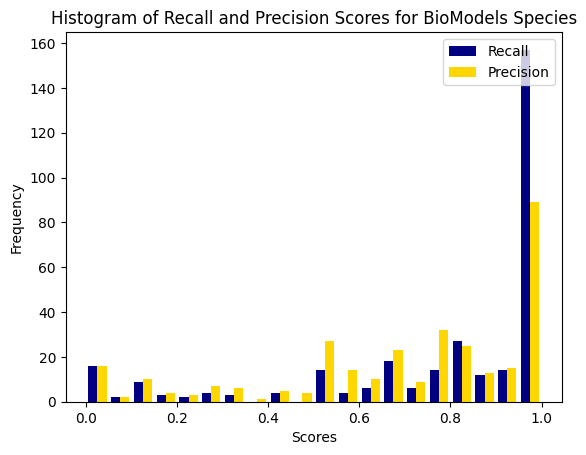

In [25]:
df1 = results_llama.groupby('model')[['recall_formula', 'precision_formula']].mean()
ax = plt.gca()
ax.hist(x=[df1['recall_formula'], df1['precision_formula']], bins=20, color=['navy', 'gold'], label=['Recall', 'Precision'])
# ax.set_ylim(0, 120)
ax.set_xlabel('Scores')
ax.set_ylabel('Frequency')
ax.set_title('Histogram of Recall and Precision Scores for BioModels Species')
ax.legend(loc='upper right')
plt.savefig(os.path.join(output_dir, 'biomd_spec_hist.png'), dpi=300, bbox_inches='tight', pad_inches=0.0)

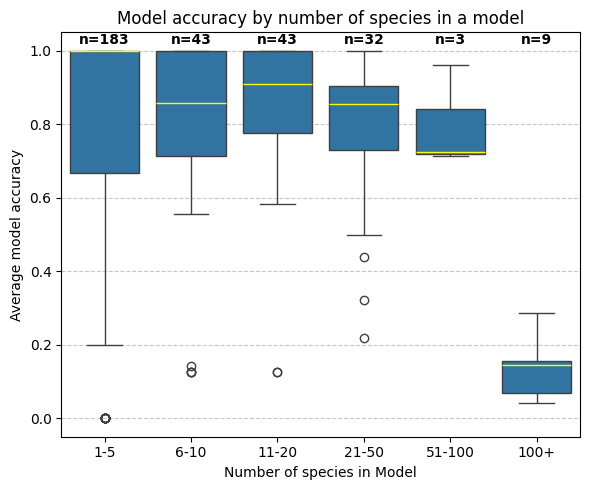

In [36]:
# Group models by number of species and calculate accuracy statistics
model_species_count = results_llama.groupby('model').size().reset_index(name='species_count')
model_accuracy = results_llama.groupby('model')['accuracy'].mean().reset_index()

# Merge the two dataframes
model_stats = pd.merge(model_species_count, model_accuracy, on='model')

# Create bins for species count to make the box plot more readable
bins = [0, 5, 10, 20, 50, 100, 1000]
labels = ['1-5', '6-10', '11-20', '21-50', '51-100', '100+']
model_stats['species_count_bin'] = pd.cut(model_stats['species_count'], bins=bins, labels=labels)

# Count number of models in each bin
bin_counts = model_stats['species_count_bin'].value_counts().reindex(labels, fill_value=0)

# Create the box plot
plt.figure(figsize=(6, 5))
ax = sns.boxplot(x='species_count_bin', y='accuracy', data=model_stats, medianprops={"color": "yellow", "linewidth": 1})

# Add counts above each box
for i, label in enumerate(labels):
    count = bin_counts[label]
    ax.text(i, 1.01, f'n={count}', ha='center', va='bottom', fontsize=10, color='black', fontweight='bold')

plt.title('Model accuracy by number of species in a model')
plt.xlabel('Number of species in Model')
plt.ylabel('Average model accuracy')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, 'accuracy_by_species_count.png'), dpi=300, bbox_inches='tight')
plt.show()


In [27]:
results_llama

,model,species_id,display_name,synonyms_LLM,reason,exist_annotation_chebi,exist_annotation_name,predictions,predictions_names,predictions_hits,recall_formula,precision_formula,recall_chebi,precision_chebi,accuracy,total_time,llm_time,query_time
0,BIOMD0000000122.xml,Ca_Nuc,Calcium in Nucleus,['calcium(2+)'],Both Ca_Nuc and Ca_Cyt are likely referring to...,['CHEBI:29108'],calcium(2+),['CHEBI:29108'],['calcium(2+)'],[1],1.0,1.000,1.0,1.000,1,16.315571,16.221407,0.094164
1,BIOMD0000000122.xml,Ca_Cyt,Calcium in Cytosol,['calcium(2+)'],Both Ca_Nuc and Ca_Cyt are likely referring to...,['CHEBI:29108'],calcium(2+),['CHEBI:29108'],['calcium(2+)'],[1],1.0,1.000,1.0,1.000,1,16.315571,16.221407,0.094164
2,BIOMD0000000579.xml,s4,cis-Aconitate,"['cis-Aconitate', 'Aconitic acid', 'Cis-aconic...",NaN,['CHEBI:32805'],cis-aconitic acid,"['CHEBI:16383', 'CHEBI:22211']","['cis-aconitate(3-)', 'aconitic acid']","[1, 1]",1.0,1.000,0.0,0.000,1,128.063863,121.243799,6.820064
3,BIOMD0000000579.xml,s188,Xylulose5P,"['Xylulose 5-phosphate', 'Xylulose-5-phosphate...",NaN,['CHEBI:16593'],L-xylulose 5-phosphate,"['CHEBI:27354', 'CHEBI:16332', 'CHEBI:57737']","['xylulose 5-phosphate', 'D-xylulose 5-phospha...","[1, 1, 1]",1.0,1.000,0.0,0.000,1,128.063863,121.243799,6.820064
4,BIOMD0000000579.xml,s49,UREA,"['Urea', 'Carbamide', 'Ureum']",NaN,['CHEBI:16199'],urea,['CHEBI:16199'],['urea'],[2],1.0,1.000,1.0,1.000,1,128.063863,121.243799,6.820064
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9645,BIOMD0000000390.xml,Pic,Pic,['UNK'],"The model is based on the Calvin-Benson cycle,...",['CHEBI:43474'],hydrogenphosphate,[],[],[],0.0,0.000,0.0,0.000,0,8.240160,7.717246,0.522914
9646,BIOMD0000000145.xml,IP3,IP3,"['inositol 1,4,5-trisphosphate', 'D-myo-inosit...","- IP3 is likely ""inositol 1,4,5-trisphosphate""...",['CHEBI:16595'],"1D-myo-inositol 1,4,5-trisphosphate",['CHEBI:16595'],"['1D-myo-inositol 1,4,5-trisphosphate']",[3],1.0,1.000,1.0,1.000,1,13.525949,13.213646,0.312303
9647,BIOMD0000000145.xml,Ca_ER,Calcium,"['calcium ion', 'Ca2+', 'calcium(2+)']","- IP3 is likely ""inositol 1,4,5-trisphosphate""...",['CHEBI:29108'],calcium(2+),"['CHEBI:29108', 'CHEBI:39124']","['calcium(2+)', 'calcium ion']","[3, 1]",1.0,1.000,1.0,0.500,1,13.525949,13.213646,0.312303
9648,BIOMD0000000145.xml,Ca_Cyt,Calcium,"['calcium ion', 'Ca2+', 'calcium(2+)']","- IP3 is likely ""inositol 1,4,5-trisphosphate""...",['CHEBI:29108'],calcium(2+),"['CHEBI:29108', 'CHEBI:39124']","['calcium(2+)', 'calcium ion']","[3, 1]",1.0,1.000,1.0,0.500,1,13.525949,13.213646,0.312303


In [37]:
# excluding models with more than 100 species 
species_count_df = results_llama.groupby('model').size().reset_index(name='count')
# Merge this count back to the original dataframe
results_llama_count = pd.merge(results_llama, species_count_df, on='model', how='left')
# Rename the column to species_count
results_llama_count = results_llama_count.rename(columns={'count': 'species_count'})
results_llama_100 = results_llama_count[results_llama_count['species_count'] <= 100]
results_llama_100.to_csv(output_dir + 'biomd_chebi_direct_llama_100.csv')
print("\n\n<LLaMa 3.3 70b Instruct - BioModels Species (excluding models with more than 100 species)>")
print_results(output_dir + 'biomd_chebi_direct_llama_100.csv')



<LLaMa 3.3 70b Instruct - BioModels Species (excluding models with more than 100 species)>
Number of models assessed: 304
Number of models with predictions: 298
Average recall (per model) using formula: 0.81
Average precision (per model) using formula: 0.72
Average recall (per model) using ChEBI ID: 0.76
Average precision (per model) using ChEBI ID: 0.39
Average accuracy (per model): 0.81
Ave. total time (per model): 17.21
Ave. total time (per element, per model): 2.03
Ave. LLM time (per model): 16.58
Ave. LLM time (per element, per model): 1.96
Average number of predictions per row: 3.1262626262626263
